In [ ]:
import marimo as mo

# Análisis exploratorio: publicaciones de Agua de Hermosillo

`publicaciones_aguah.csv` tiene una fila por publicación de la página de Facebook de
Agua de Hermosillo (diciembre de 2020 a septiembre de 2026): texto, OCR del volante,
reacciones, comentarios y variables derivadas como el tipo de evento y la ventana de
afectación anunciada. Es la tabla central del proyecto: de ella salen las menciones de
`ubicaciones_aviso` y la señal de molestia (`reactions_angry`, `angry_share`).

## Objetivos

1. Auto EDA con ydata-profiling como primer vistazo, publicado en `docs/eda/`.
2. Datos faltantes: cuántos, de qué mecanismo y qué hacer con ellos.
3. Anomalías con dos familias de técnicas: regla de Tukey (univariada) y PyOD
   (IForest, ECOD y LOF, multivariadas).
4. Relaciones entre variables por visualización.
5. Correlación entre variables numéricas y categóricas.
6. Reducción a 2D con PCA, t-SNE y UMAP, comparadas entre sí.
7. Preguntas para los usuarios que salen de lo anterior.

In [ ]:
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

from project_name.eda import (
    CATEGORICAL,
    NEUTRAL,
    agreement_table,
    correlation_ratio,
    cramers_v_matrix,
    embed_2d,
    embedding_quality,
    iqr_outliers,
    missing_table,
    plot_embeddings,
    plot_heatmap,
    processed_path,
    pyod_outliers,
    run_ydata_profile,
    ydata_summary,
)

DATASET = "publicaciones_aguah"
pd.set_option("display.max_rows", 60)

## 1. Auto EDA con ydata-profiling

El reporte completo está en
[`docs/eda/publicaciones_aguah.html`](../../docs/eda/publicaciones_aguah.html). Lo genera
`scripts/ydata_profile.py` en un entorno aislado (`uv run --script`), porque
ydata-profiling 4.18 exige pandas<3 y el proyecto usa pandas 3. La celda siguiente solo
lo regenera si el CSV cambió; aquí se muestra el resumen y las alertas, que son las que
guían el resto del notebook.

In [ ]:
report_html = run_ydata_profile(DATASET)
ydata_overview, ydata_alerts = ydata_summary(DATASET)
ydata_overview.to_frame("valor")

,valor
filas,5200
columnas,31
celdas faltantes,8312
% celdas faltantes,5.16
columnas con faltantes,3
filas duplicadas,0
memoria (MB),12.38
tipo Categorical,3
tipo DateTime,2
tipo Numeric,19


In [ ]:
ydata_alerts.groupby("alerta")["columna"].agg(["count", lambda s: ", ".join(s)]).set_axis(
    ["columnas", "cuáles"], axis=1
)

,columnas,cuáles
alerta,,
alta correlación,16,"angry_share, comments_count, has_image, has_ocr_text, iso_week, likes_count, month, ocr_status, reactions_angry, reactions_haha, reactions_like, reactions_total, shares_count, source_slug, top_comment_likes, year"
ceros,12,"angry_share, comments_count, day_of_week, reactions_angry, reactions_care, reactions_haha, reactions_like, reactions_love, reactions_sad, reactions_wow, shares_count, top_comment_likes"
desbalanceada,2,"event_type, has_text"
faltantes,2,"announced_duration_hours, announced_start_at"
muy sesgada,4,"likes_count, reactions_like, reactions_love, reactions_total"
valores únicos,1,published_at


Lo que señala el reporte y dónde se revisa abajo:

- Faltantes altos en `announced_start_at` (70%) y `announced_duration_hours` (89%):
  sección 2.
- Conteos muy sesgados y con muchos ceros (reacciones, comentarios, compartidos): por
  eso las anomalías y las correlaciones se calculan sobre `log1p`, sección 3.
- Alta correlación entre reacciones, comentarios y `likes_count`; y entre `has_image`,
  `has_ocr_text` y `ocr_status`: sección 5, que separa redundancias de relaciones.
- `event_type` desbalanceada: "otro" es la clase mayoritaria; sección 6.

## 2. Datos faltantes

En el CSV una cadena vacía y un nulo se escriben igual, y `pd.read_csv` convierte ambos
en `NaN`. En este dataset el texto vacío es un dato ("la publicación no trae texto", que
ya dicen `has_text` y `has_ocr_text`), así que se lee con `keep_default_na=False` y solo
se aceptan nulos en las columnas que pueden tenerlos. La tabla separa nulos de vacíos.

In [ ]:
posts = pd.read_csv(
    processed_path(DATASET),
    dtype={"post_id": str},
    keep_default_na=False,
    na_values={
        "angry_share": [""],
        "announced_duration_hours": [""],
        "announced_start_at": [""],
    },
    parse_dates=["published_at", "announced_start_at"],
)
posts.shape

In [ ]:
missing_table(posts)

,nulos,vacios,% nulos,% vacios
announced_duration_hours,4643,0,89.29,0.00
announced_start_at,3640,0,70.00,0.00
angry_share,29,0,0.56,0.00
text,0,45,0.00,0.87
ocr_text,0,2853,0.00,54.87
top_comment_text,0,1225,0.00,23.56


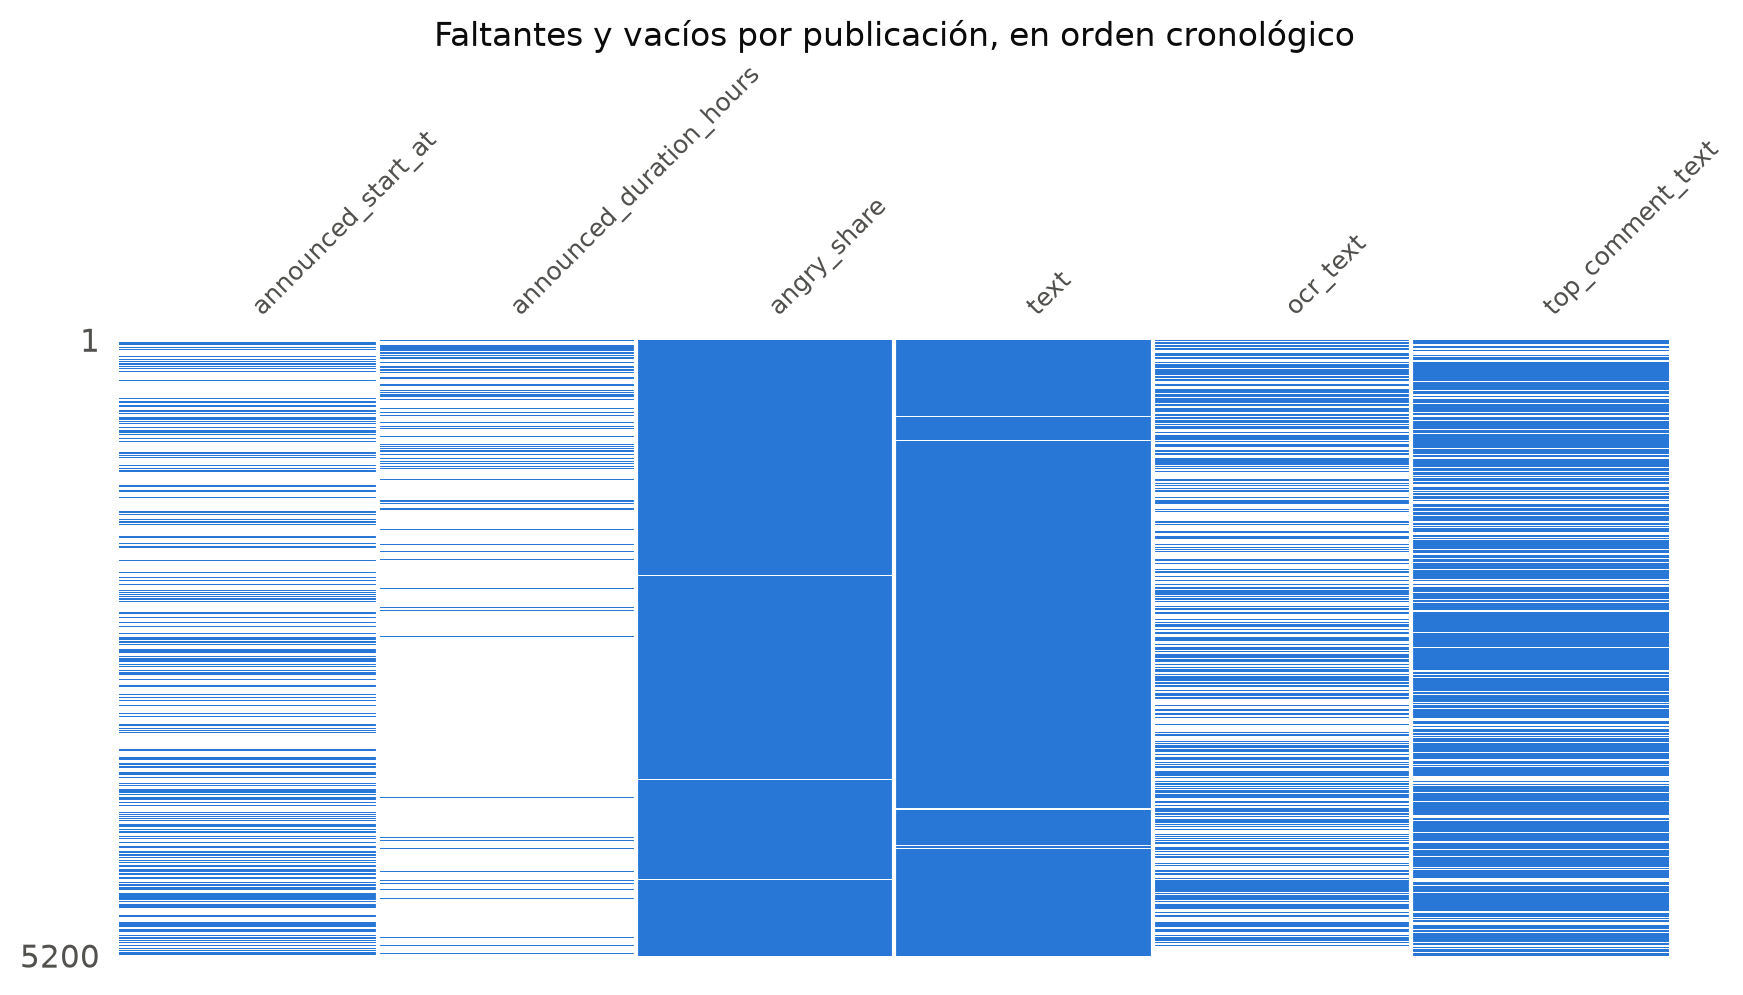

In [ ]:
# Matriz de faltantes ordenada por fecha: cada línea blanca es una publicación sin dato.
_columns = [
    "announced_start_at",
    "announced_duration_hours",
    "angry_share",
    "text",
    "ocr_text",
    "top_comment_text",
]
_view = posts.sort_values("published_at")[_columns].replace("", None)
_ax = msno.matrix(
    _view, figsize=(10, 4), fontsize=9, sparkline=False, color=(0.16, 0.47, 0.84)
)
_ax.set_title("Faltantes y vacíos por publicación, en orden cronológico")
plt.gcf()

Cada faltante tiene una causa que se puede verificar con otra columna. La tabla siguiente
prueba cada regla sobre las 5,200 filas:

In [ ]:
structural_rules = {
    "angry_share es nulo si y solo si reactions_total = 0": (
        posts["angry_share"].isna() == (posts["reactions_total"] == 0)
    ),
    "text vacío si y solo si has_text es falso": (posts["text"] == "") == ~posts["has_text"],
    "ocr_text vacío si y solo si has_ocr_text es falso": (
        (posts["ocr_text"] == "") == ~posts["has_ocr_text"]
    ),
    "announced_start_at nulo si y solo si has_announced_start_at es falso": (
        posts["announced_start_at"].isna() == ~posts["has_announced_start_at"]
    ),
    "sin comentarios implica top_comment_text vacío": (
        (posts["comments_count"] > 0) | (posts["top_comment_text"] == "")
    ),
}
pd.DataFrame(
    {
        "filas que la cumplen": {rule: int(ok.sum()) for rule, ok in structural_rules.items()},
        "se cumple siempre": {rule: bool(ok.all()) for rule, ok in structural_rules.items()},
    }
)

,filas que la cumplen,se cumple siempre
angry_share es nulo si y solo si reactions_total = 0,5200,True
text vacío si y solo si has_text es falso,5200,True
ocr_text vacío si y solo si has_ocr_text es falso,5200,True
announced_start_at nulo si y solo si has_announced_start_at es falso,5200,True
sin comentarios implica top_comment_text vacío,5200,True


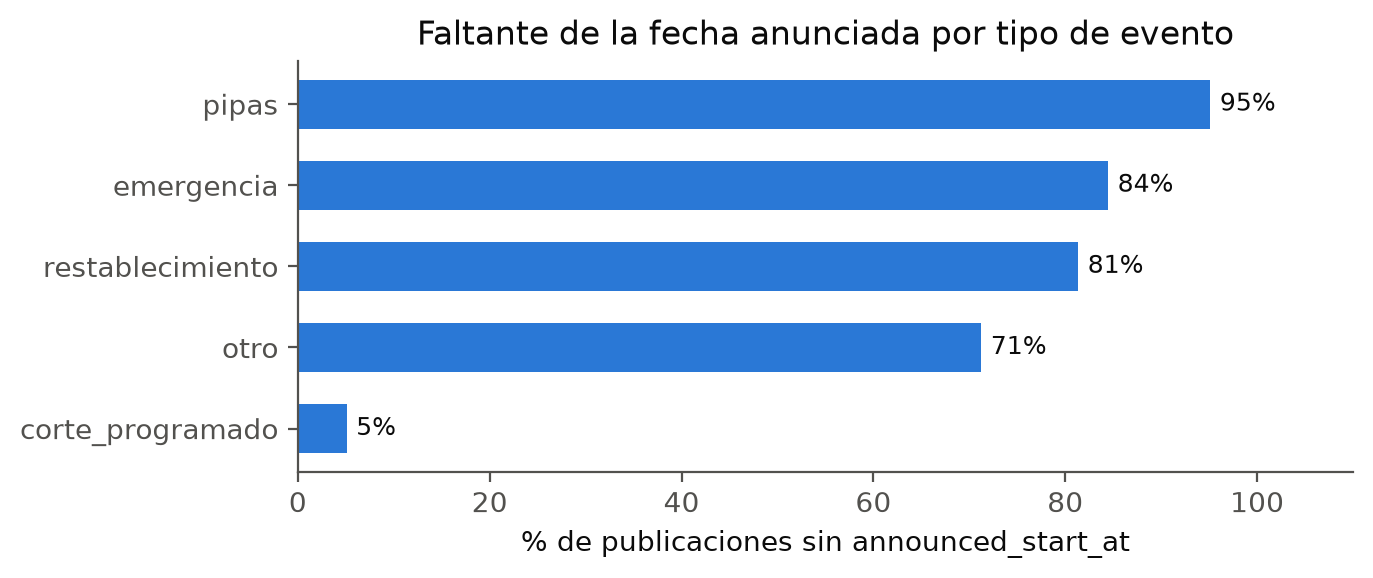

In [ ]:
# ¿El faltante de la fecha anunciada depende del tipo de evento? (MAR frente a MCAR)
_rate = (
    posts.assign(missing=posts["announced_start_at"].isna())
    .groupby("event_type")["missing"]
    .mean()
    .sort_values()
)
_fig, _ax = plt.subplots(figsize=(7, 3))
_ax.barh(_rate.index, 100 * _rate.to_numpy(), color="#2a78d6", height=0.6)
for _y, _value in enumerate(_rate.to_numpy()):
    _ax.text(100 * _value + 1, _y, f"{100 * _value:.0f}%", va="center", fontsize=9)
_ax.set_xlim(0, 110)
_ax.set_xlabel("% de publicaciones sin announced_start_at")
_ax.set_title("Faltante de la fecha anunciada por tipo de evento")
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

Mecanismo de cada faltante:

| Columna | Nulos o vacíos | Mecanismo | Decisión |
|---|---:|---|---|
| `angry_share` | 29 (0.6%) | Estructural: no hay reacciones, la proporción no está definida | Dejar nulo; usar 0 solo en las técnicas que no aceptan nulos |
| `announced_start_at` | 3,640 (70%) | MAR: depende del tipo de evento (5% en `corte_programado`, 84% en `emergencia`) | No imputar; `has_announced_start_at` ya es la variable útil |
| `announced_duration_hours` | 4,643 (89%) | El aviso no declara plazo | No imputar; analizar solo en el 11% que lo declara |
| `text` | 45 vacíos (0.9%) | Publicaciones solo con imagen | No es faltante |
| `ocr_text` | 2,853 vacíos (55%) | 1,979 sin imagen y 874 con imagen sin texto | No es faltante |
| `top_comment_text` | 1,225 vacíos (24%) | 657 sin comentarios; 568 con comentarios sin destacado | No es faltante |

Ninguna columna se elimina ni se imputa: los faltantes son información (el aviso no
declara fecha) y las técnicas que no aceptan nulos usan variables derivadas
(`has_announced_start_at`, `angry_share` con 0).

### Periodos sin publicaciones

Además de celdas vacías, a una serie de tiempo le pueden faltar periodos completos. Las
publicaciones vienen de 7 exportaciones del scraper (`source_slug`), cada una con un rango
de fechas; un hueco entre rangos o dentro de un rango sería un faltante que no aparece en
ninguna columna.

In [ ]:
posts.groupby("source_slug")["published_at"].agg(["min", "max", "count"]).assign(
    days=lambda frame: (frame["max"] - frame["min"]).dt.days
)

,min,max,count,days
source_slug,,,,
2020-12-07-to-2022-05-09,2020-12-07 08:25:59,2022-05-09 19:27:50,714,518
2022-05-11-to-2023-06-28,2022-05-11 13:18:02,2023-06-28 13:43:18,714,413
2023-06-30-to-2024-04-05,2023-06-30 10:07:14,2024-04-05 13:25:11,714,280
2024-04-07-to-2024-12-31,2024-04-19 13:04:47,2024-12-30 16:18:00,696,255
2025-01-01-to-2025-06-02,2025-01-02 12:16:00,2025-05-31 11:16:10,649,148
2025-06-03-to-2025-10-22,2025-06-03 14:10:38,2025-10-21 15:57:20,714,140
2025-10-23-to-2026-09-14,2025-10-23 11:36:50,2026-09-14 14:31:14,999,326


In [ ]:
# Huecos de más de 7 días entre publicaciones consecutivas.
_ordered = posts.sort_values("published_at")["published_at"].reset_index(drop=True)
_gap = _ordered.diff()
publication_gaps = pd.DataFrame(
    {
        "desde": _ordered.shift()[_gap > pd.Timedelta(days=7)],
        "hasta": _ordered[_gap > pd.Timedelta(days=7)],
    }
).assign(dias=lambda frame: (frame["hasta"] - frame["desde"]).dt.days)
publication_gaps

,desde,hasta,dias
2142,2024-04-05 13:25:11,2024-04-19 13:04:47,13


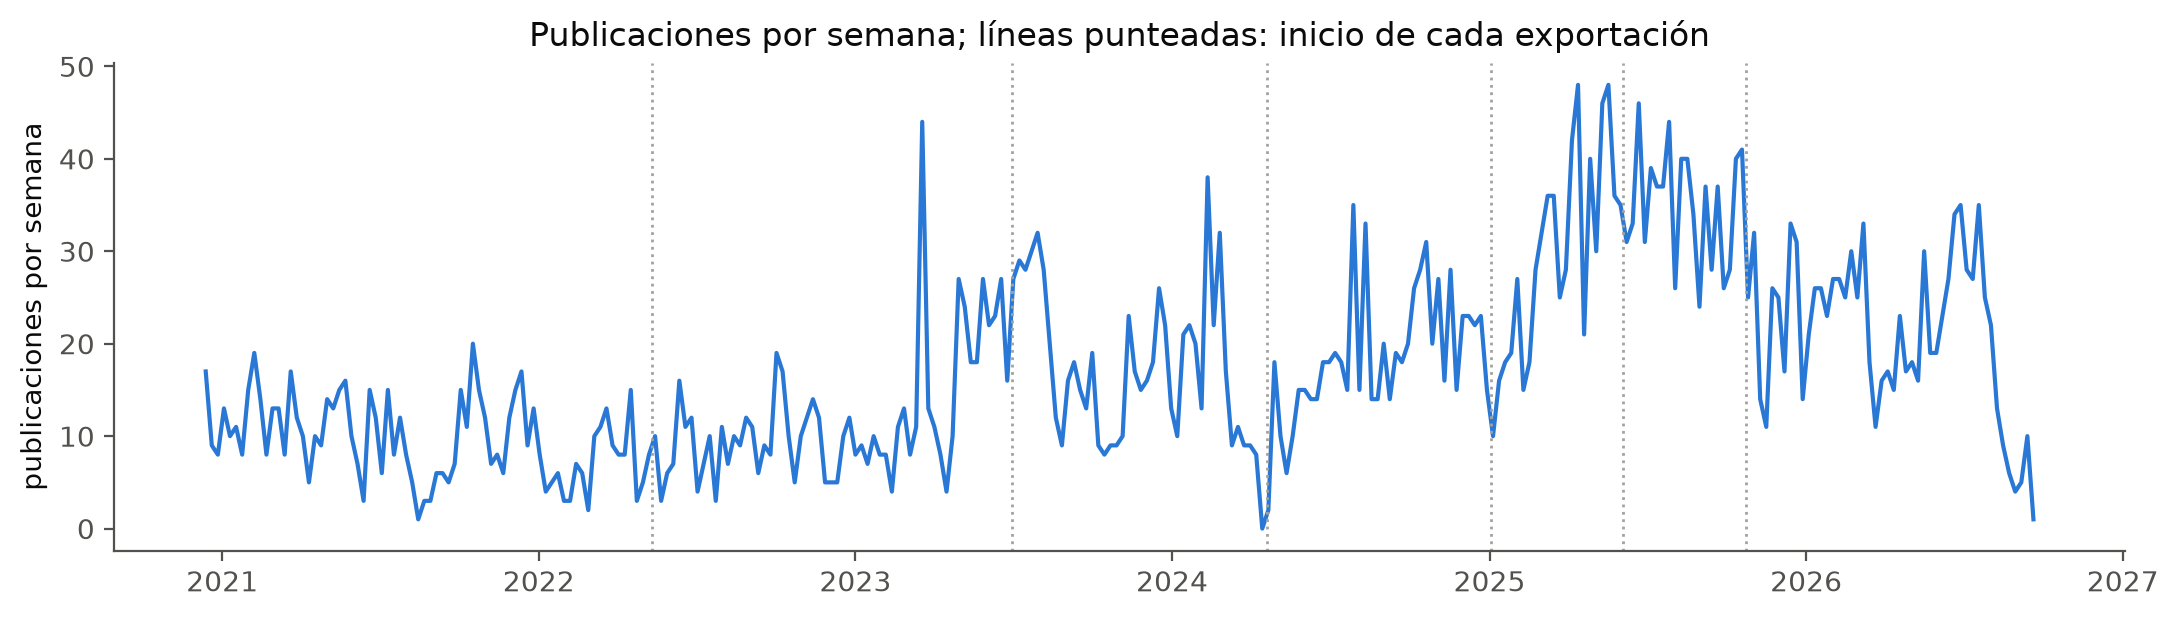

In [ ]:
_weekly = posts.set_index("published_at").resample("W").size()
_fig, _ax = plt.subplots(figsize=(11, 3.2))
_ax.plot(_weekly.index, _weekly.to_numpy(), color="#2a78d6", linewidth=1.5)
for _start in posts.groupby("source_slug")["published_at"].min().sort_values().iloc[1:]:
    _ax.axvline(_start, color=NEUTRAL, linewidth=1, linestyle=":")
_ax.set_ylabel("publicaciones por semana")
_ax.set_title("Publicaciones por semana; líneas punteadas: inicio de cada exportación")
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

Las exportaciones se tocan sin huecos salvo una: entre el 5 y el 19 de abril de 2024 no
hay ninguna publicación, aunque la exportación `2024-04-07-to-2024-12-31` empieza el 7. Al
final de la serie, agosto (36) y septiembre de 2026 (16, hasta el día 14) caen respecto a
los meses previos (120 a 132). Ambos tramos deben tratarse como cobertura incompleta en
cualquier serie mensual, no como meses tranquilos.

## 3. Anomalías

Las variables de interacción (reacciones, comentarios, compartidos) son conteos con colas
largas: la mediana de `reactions_total` es 12 y el máximo 5,661. Sobre la escala original
cualquier método marcaría solo la cola, así que todo se calcula sobre `log1p` y, para los
métodos multivariados, estandarizado.

Dos familias de técnicas:

1. Univariada: regla de Tukey (fuera de Q1 - 1.5 IQR o Q3 + 1.5 IQR) por variable.
2. Multivariada con PyOD, tres detectores con supuestos distintos: IForest (aislamiento
   con cortes aleatorios), ECOD (colas de las distribuciones empíricas) y LOF (densidad
   local respecto a los vecinos). Con `contamination=0.02` cada uno marca 104
   publicaciones; una publicación es anómala si la marcan al menos dos.

In [ ]:
engagement_columns = [
    "reactions_total",
    "reactions_angry",
    "comments_count",
    "shares_count",
    "top_comment_likes",
]
engagement_log = np.log1p(posts[engagement_columns]).assign(
    angry_share=posts["angry_share"].fillna(0)
)
engagement_scaled = pd.DataFrame(
    StandardScaler().fit_transform(engagement_log),
    columns=engagement_log.columns,
    index=engagement_log.index,
)

In [ ]:
tukey_flags = pd.DataFrame(
    {column: iqr_outliers(engagement_log[column]) for column in engagement_log}
)
tukey_flags.sum().rename("anómalas (Tukey, log1p)").to_frame().assign(
    porcentaje=lambda frame: (100 * frame.iloc[:, 0] / len(tukey_flags)).round(1)
)

,"anómalas (Tukey, log1p)",porcentaje
reactions_total,147,2.8
reactions_angry,122,2.3
comments_count,16,0.3
shares_count,97,1.9
top_comment_likes,549,10.6
angry_share,60,1.2


In [ ]:
pyod_result = pyod_outliers(engagement_scaled, contamination=0.02)
_flags = pyod_result.filter(like="_outlier").assign(tukey_any=tukey_flags.any(axis=1))
agreement_table(_flags)

,iforest_outlier,ecod_outlier,lof_outlier,tukey_any
iforest_outlier,1.00,0.58,0.06,0.15
ecod_outlier,0.58,1.00,0.05,0.15
lof_outlier,0.06,0.05,1.00,0.02
tukey_any,0.15,0.15,0.02,1.00


In [ ]:
pyod_result["votes"].value_counts().sort_index().rename("publicaciones").to_frame()

,publicaciones
votes,
0,4976
1,147
2,67
3,10


IForest y ECOD coinciden en 58% de sus marcas (Jaccard): ambos buscan publicaciones con
valores extremos en varias variables a la vez. LOF casi no coincide con nadie (6%): marca
puntos en zonas poco densas aunque no sean extremos, por ejemplo publicaciones con muchas
reacciones pero cero enojo. Tukey marca 701 publicaciones con al menos una variable fuera
de rango, la mayoría por `top_comment_likes`, que tiene 66% de ceros y un IQR casi nulo:
la regla univariada sobre conteos con muchos ceros es demasiado sensible.

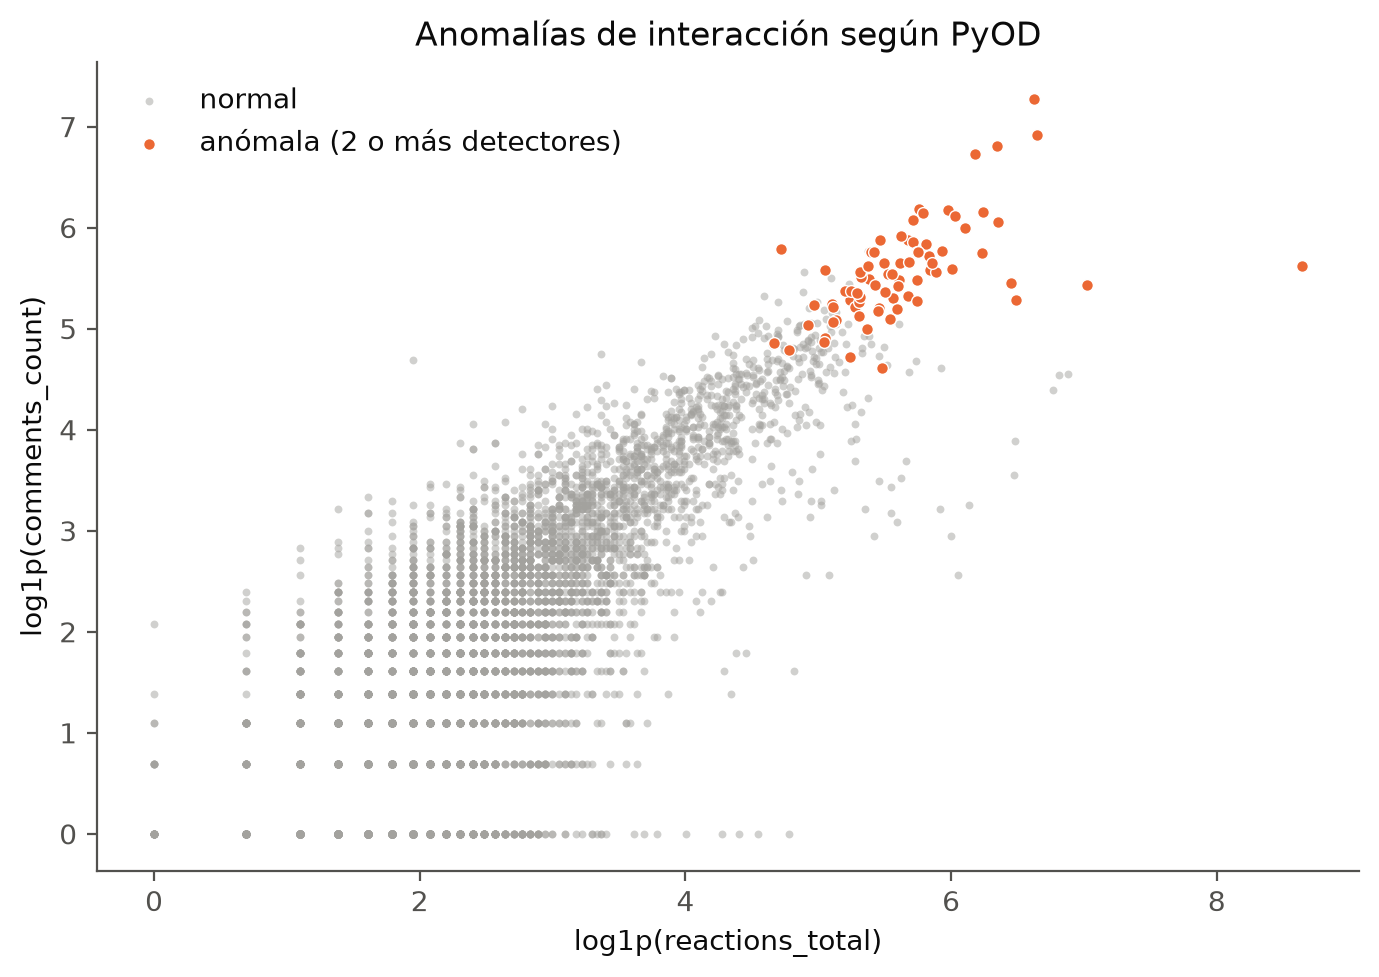

In [ ]:
_is_outlier = pyod_result["votes"] >= 2
_fig, _ax = plt.subplots(figsize=(7, 5))
_ax.scatter(
    engagement_log.loc[~_is_outlier, "reactions_total"],
    engagement_log.loc[~_is_outlier, "comments_count"],
    s=8,
    color=NEUTRAL,
    alpha=0.5,
    linewidths=0,
    label="normal",
)
_ax.scatter(
    engagement_log.loc[_is_outlier, "reactions_total"],
    engagement_log.loc[_is_outlier, "comments_count"],
    s=18,
    color=CATEGORICAL[1],
    edgecolors="white",
    linewidths=0.5,
    label="anómala (2 o más detectores)",
)
_ax.set_xlabel("log1p(reactions_total)")
_ax.set_ylabel("log1p(comments_count)")
_ax.set_title("Anomalías de interacción según PyOD")
_ax.legend(frameon=False)
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

In [ ]:
outlier_posts = posts.loc[
    pyod_result["votes"] >= 2,
    ["published_at", "event_type", *engagement_columns, "angry_share", "text"],
].assign(text=lambda frame: frame["text"].str.replace(r"\s+", " ", regex=True).str[:70])
outlier_posts.sort_values("reactions_total", ascending=False).head(15)

,published_at,event_type,reactions_total,reactions_angry,comments_count,shares_count,top_comment_likes,angry_share,text
4350,2026-07-07 18:59:29,otro,5661,28,274,189,90,0.004946,#AguaHInforma Lluvias y fuertes vientos en la zona de El Novillo provo
4254,2026-07-30 12:06:15,otro,1123,73,228,52,49,0.065004,Continúan efectos por alta turbiedad en el agua que llega a El Molinit
1563,2024-02-09 19:55:02,corte_programado,768,168,1005,238,0,0.218750,El área Operativa de Agua de Hermosillo informa a la ciudadanía que se
1562,2024-02-10 09:27:40,corte_programado,754,505,1440,86,0,0.669761,AGUA DE HERMOSILLO INFORMA El proceso de distribución de agua potable
1386,2022-06-13 15:56:10,otro,655,3,197,202,12,0.004580,"En apoyo a las familias hermosillenses, el próximo 20 de junio daremos"
406,2021-06-14 08:23:07,emergencia,633,4,232,947,78,0.006319,#AguaParaTodos
4664,2026-04-01 13:07:29,otro,573,402,424,62,57,0.701571,"Aviso importante: Agua de Hermosillo informa que, debido a complicacio"
1415,2022-05-23 14:11:36,otro,567,338,907,57,5,0.596120,
4250,2026-08-02 11:13:03,otro,510,279,469,65,67,0.547059,Equipos de bombeo del Acueducto Independencia resultaron afectados con
4251,2026-08-01 12:57:48,otro,509,154,312,94,47,0.302554,Elevado arrastre de sedimentos mantiene contingencia en el servicio de


In [ ]:
pd.DataFrame(
    {
        "% en anomalías": outlier_posts["event_type"].value_counts(normalize=True),
        "% en todo el dataset": posts["event_type"].value_counts(normalize=True),
    }
).mul(100).round(1)

,% en anomalías,% en todo el dataset
event_type,,
otro,57.1,75.4
emergencia,27.3,15.6
corte_programado,9.1,5.7
restablecimiento,5.2,2.6
pipas,1.3,0.8


In [ ]:
outlier_posts.groupby(outlier_posts["published_at"].dt.to_period("M")).size().sort_values(
    ascending=False
).head(8).rename("anomalías por mes").to_frame()

,anomalías por mes
published_at,
2024-08,7
2024-02,7
2026-04,6
2024-07,5
2025-04,5
2026-08,5
2025-08,4
2024-11,4


Las 77 publicaciones anómalas no son errores de captura: son avisos con interacción real
muy alta (las mayores: lluvias en la zona de El Novillo y turbiedad en julio de 2026,
rupturas de la tubería principal en febrero de 2024). Están sobrerrepresentadas en
`emergencia` (27% frente a 16%) y `corte_programado` (9% frente a 6%) y se reparten en
muchos meses: ninguno tiene más de 7. Son justo la señal que el proyecto busca, así que se
conservan; para modelar conviene usar `log1p` o escalas robustas en lugar de recortarlas.

Otra clase de anomalía es la de consistencia entre columnas. Se revisan reglas que
deberían cumplirse por construcción:

In [ ]:
_reaction_columns = [
    column
    for column in posts
    if column.startswith("reactions_") and column != "reactions_total"
]
consistency_rules = {
    "likes_count es igual a reactions_total": posts["likes_count"] == posts["reactions_total"],
    "la suma de reacciones es reactions_total": (
        posts[_reaction_columns].sum(axis=1) == posts["reactions_total"]
    ),
    "con imagen implica OCR corrido": ~posts["has_image"]
    | (posts["ocr_status"] == "ocr_success"),
    "con OCR corrido implica imagen": (posts["ocr_status"] != "ocr_success")
    | posts["has_image"],
    "publicada entre 6:00 y 23:59": posts["hour_of_day"] >= 6,
}
pd.DataFrame(
    {
        "filas que no la cumplen": {
            rule: int((~ok).sum()) for rule, ok in consistency_rules.items()
        },
    }
)

,filas que no la cumplen
likes_count es igual a reactions_total,0
la suma de reacciones es reactions_total,0
con imagen implica OCR corrido,19
con OCR corrido implica imagen,0
publicada entre 6:00 y 23:59,16


- `likes_count` es una copia exacta de `reactions_total` en las 5,200 filas: el scraper
  llama "likes" al total de reacciones. Es redundante y se puede quitar del dataset tidy.
- 19 publicaciones tienen imagen pero `ocr_status = skipped_no_image`: la imagen no se
  descargó o el manifiesto no la incluyó. Es un hueco del OCR por revisar en el proyecto 1.
- 16 publicaciones salen entre las 0:00 y las 5:59. Son avisos reales de madrugada (y
  cuatro de un concurso publicadas a la 1:00), no un error de zona horaria.

## 4. Relaciones entre variables por visualización

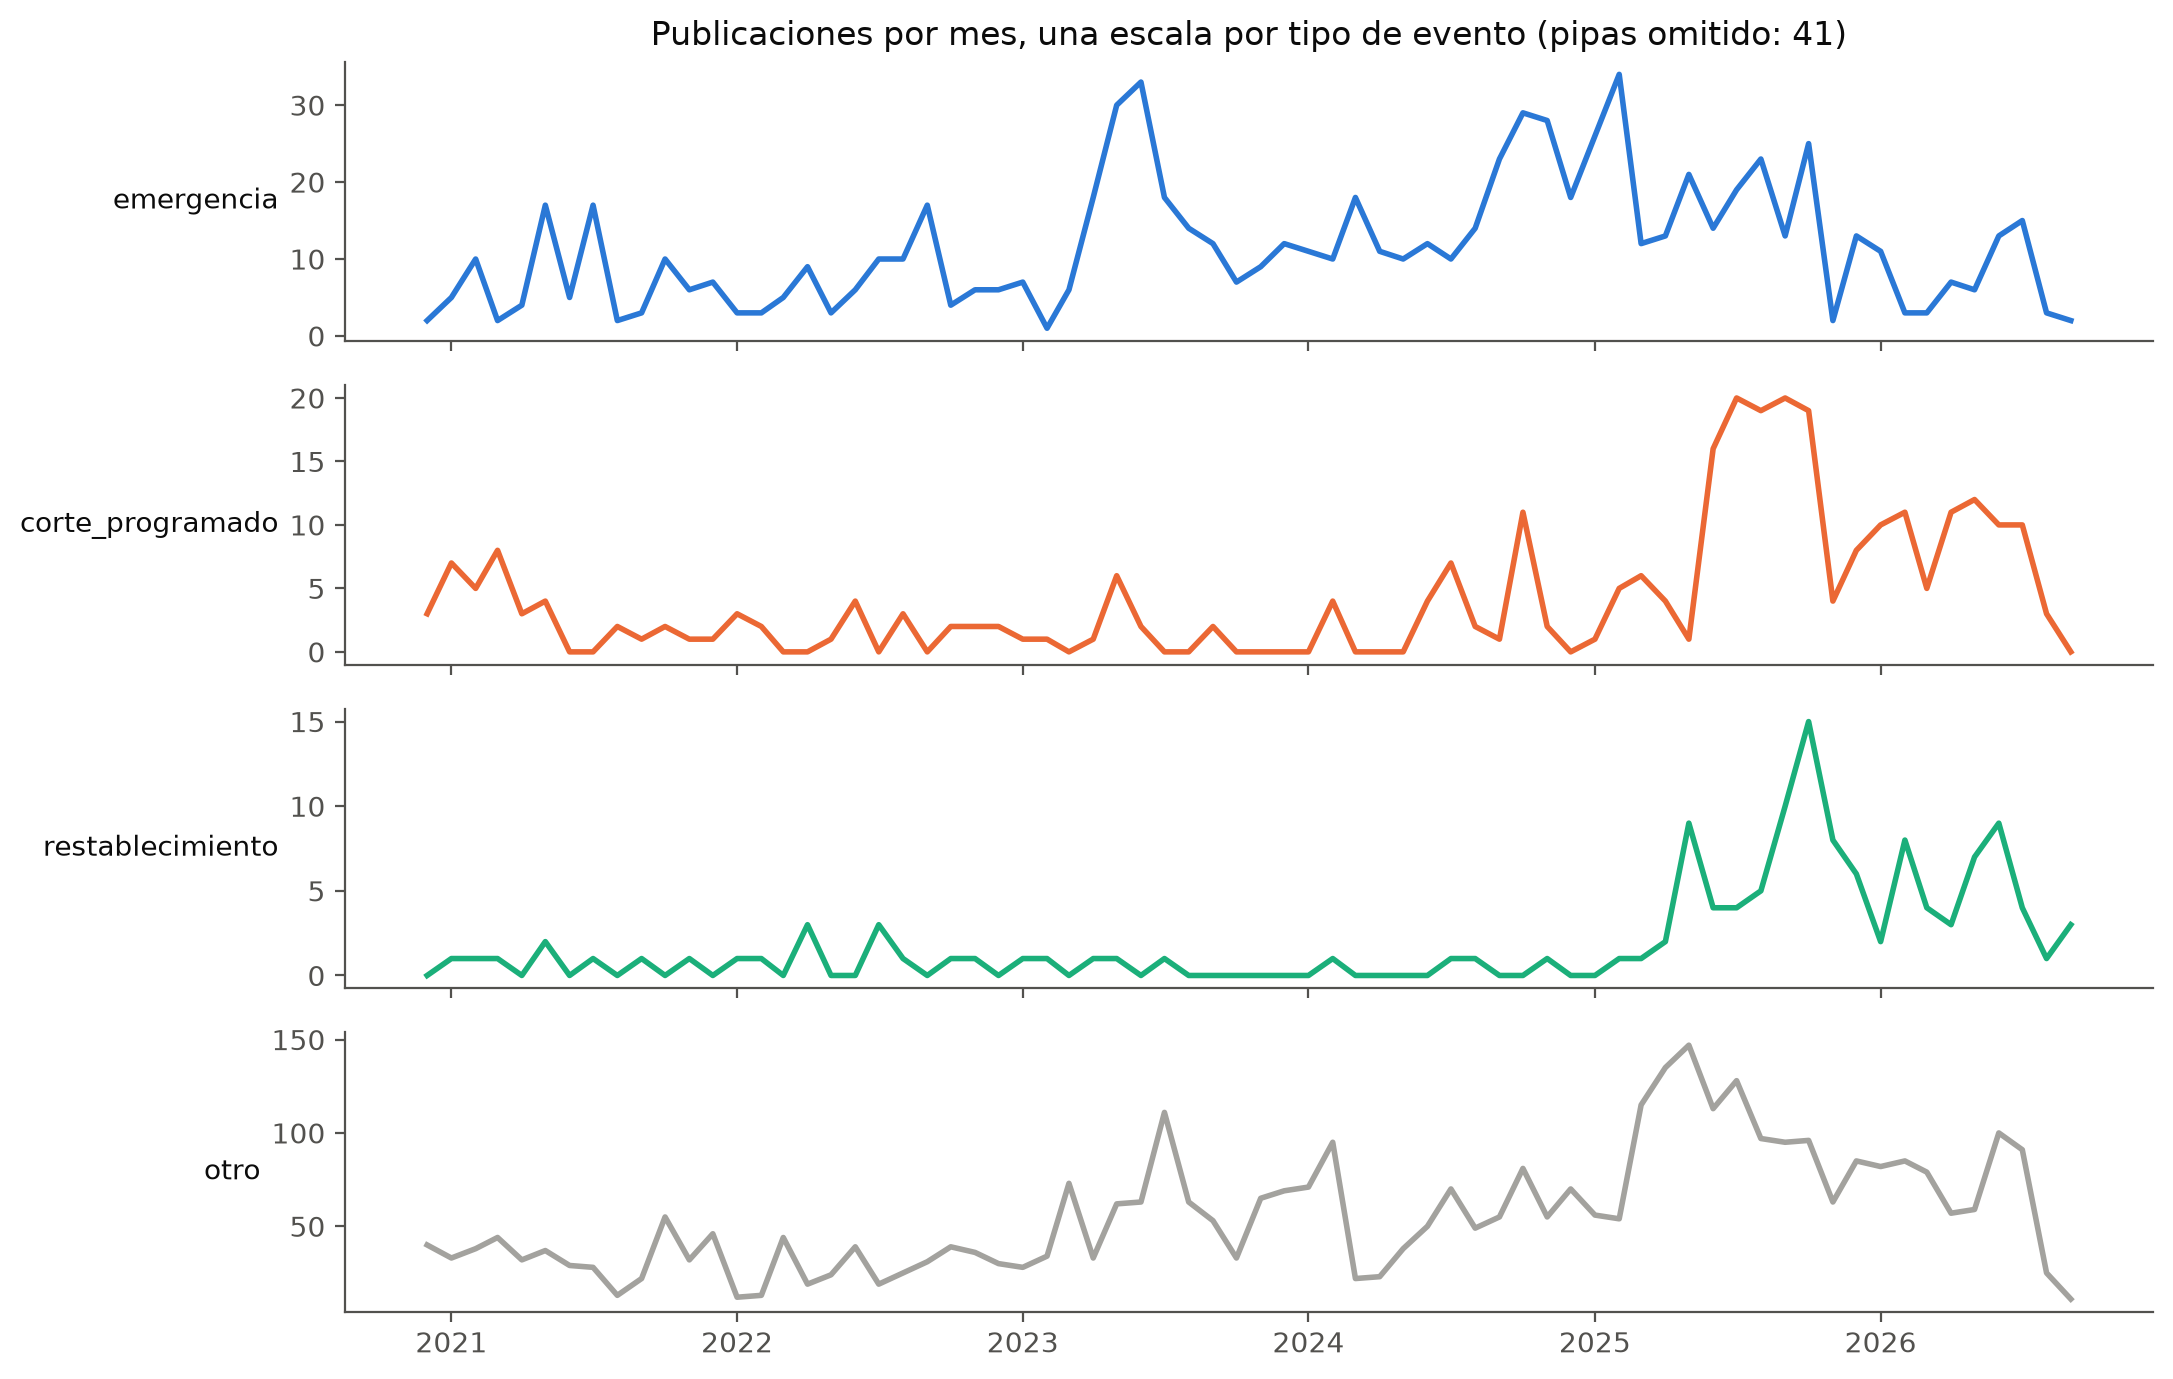

In [ ]:
# Publicaciones por mes y tipo de evento; "otro" en gris para que no domine.
_monthly = (
    posts.groupby([posts["published_at"].dt.to_period("M"), "event_type"])
    .size()
    .unstack(fill_value=0)
)
_monthly.index = _monthly.index.to_timestamp()
_colors = {
    "emergencia": CATEGORICAL[0],
    "corte_programado": CATEGORICAL[1],
    "restablecimiento": CATEGORICAL[2],
    "otro": NEUTRAL,
}
_fig, _axes = plt.subplots(len(_colors), 1, figsize=(11, 7), sharex=True)
for _ax, (_event, _color) in zip(_axes, _colors.items()):
    _ax.plot(_monthly.index, _monthly[_event], color=_color, linewidth=2)
    _ax.set_ylabel(_event, rotation=0, ha="right", va="center")
    _ax.spines[["top", "right"]].set_visible(False)
_axes[0].set_title("Publicaciones por mes, una escala por tipo de evento (pipas omitido: 41)")
_fig.tight_layout()
_fig

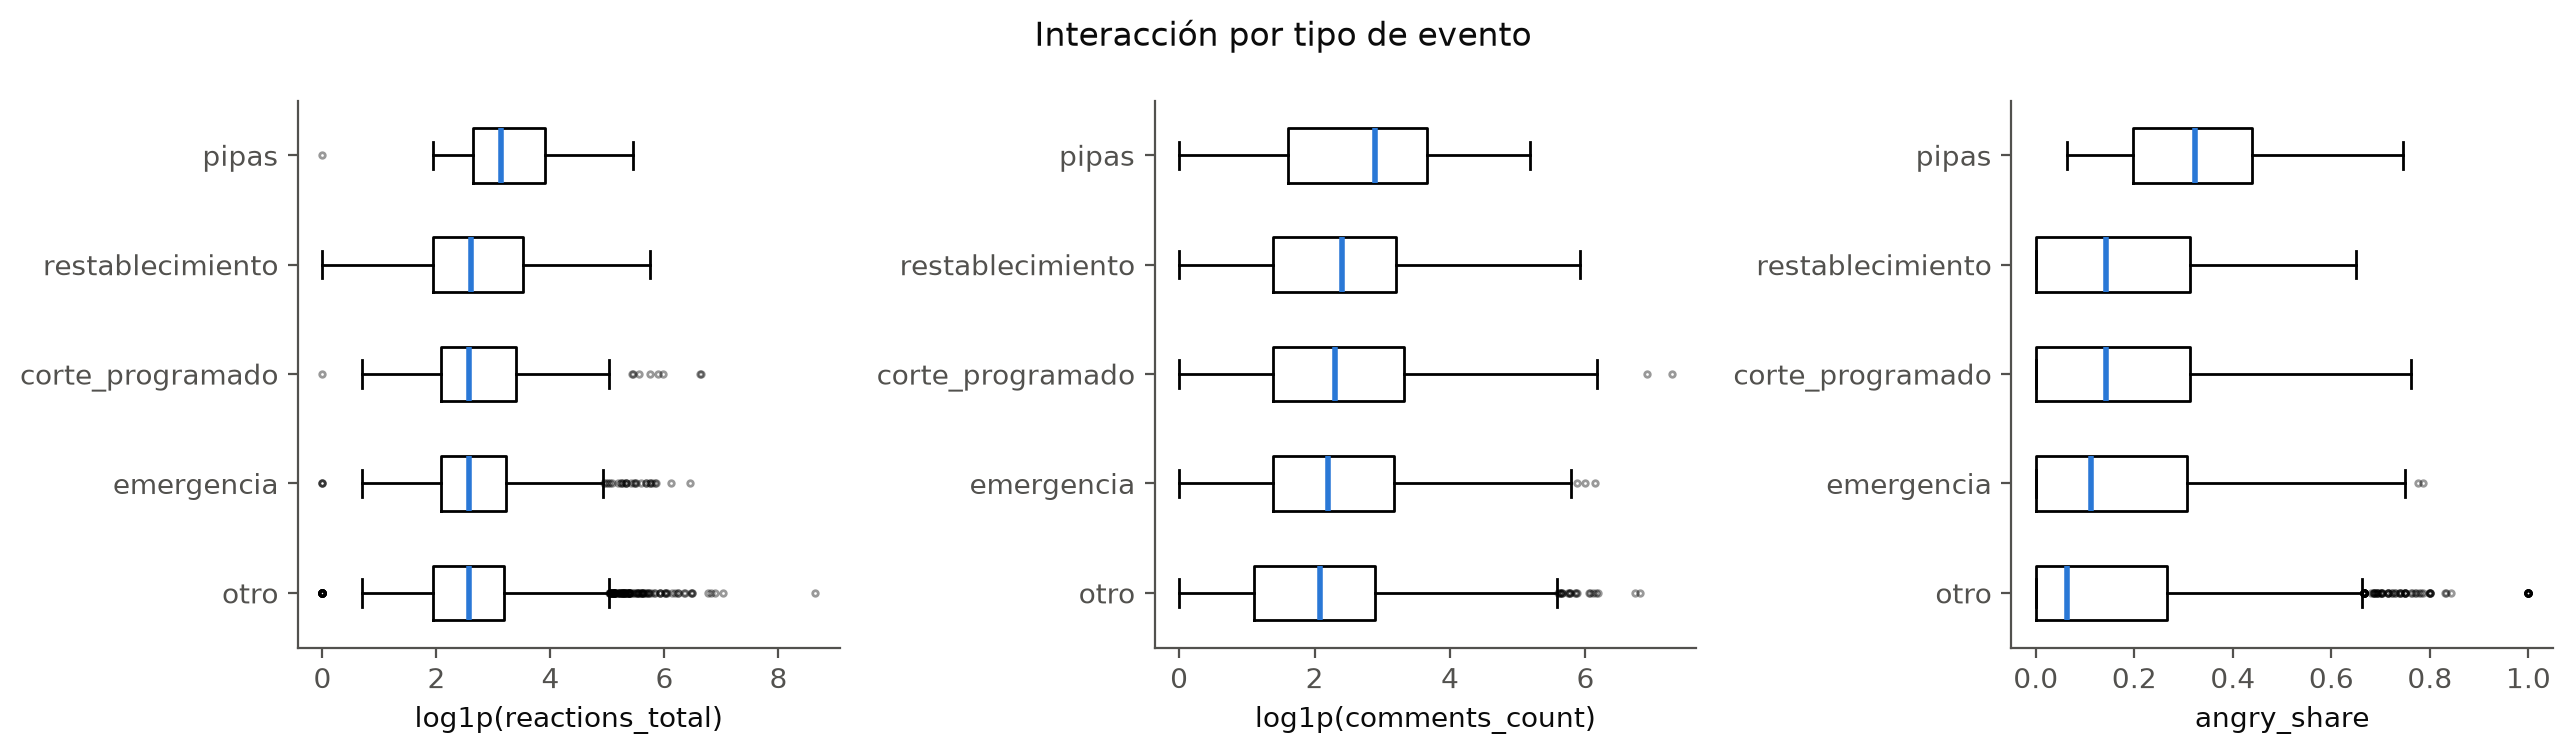

In [ ]:
# Interacción por tipo de evento, en escala log1p.
_order = posts["event_type"].value_counts().index.tolist()
_metrics = {
    "log1p(reactions_total)": np.log1p(posts["reactions_total"]),
    "log1p(comments_count)": np.log1p(posts["comments_count"]),
    "angry_share": posts["angry_share"],
}
_fig, _axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for _ax, (_label, _values) in zip(_axes, _metrics.items()):
    _groups = [_values[posts["event_type"] == _event].dropna() for _event in _order]
    _ax.boxplot(
        _groups,
        tick_labels=_order,
        orientation="horizontal",
        widths=0.5,
        flierprops={"markersize": 2, "alpha": 0.4},
        medianprops={"color": "#2a78d6", "linewidth": 2},
    )
    _ax.set_xlabel(_label)
    _ax.spines[["top", "right"]].set_visible(False)
_fig.suptitle("Interacción por tipo de evento")
_fig.tight_layout()
_fig

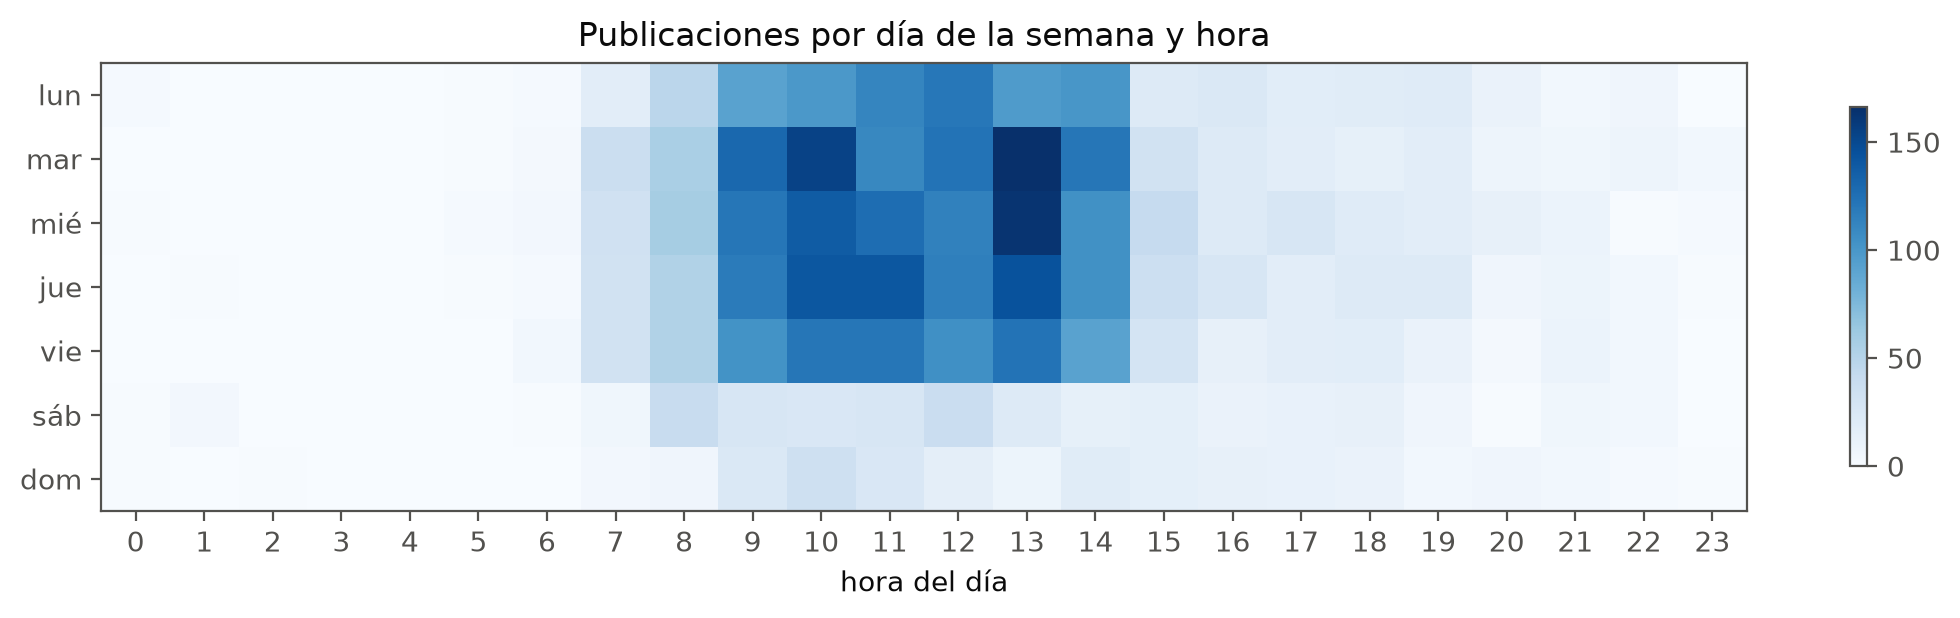

In [ ]:
# Cuándo publica la página: hora del día por día de la semana.
_counts = posts.pivot_table(
    index="day_of_week", columns="hour_of_day", values="post_id", aggfunc="count", fill_value=0
).reindex(columns=range(24), fill_value=0)
_fig, _ax = plt.subplots(figsize=(11, 3.2))
_image = _ax.imshow(_counts.to_numpy(), cmap="Blues", aspect="auto")
_ax.set_yticks(range(7), ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"])
_ax.set_xticks(range(24))
_ax.set_xlabel("hora del día")
_ax.set_title("Publicaciones por día de la semana y hora")
_fig.colorbar(_image, ax=_ax, shrink=0.8)
_fig.tight_layout()
_fig

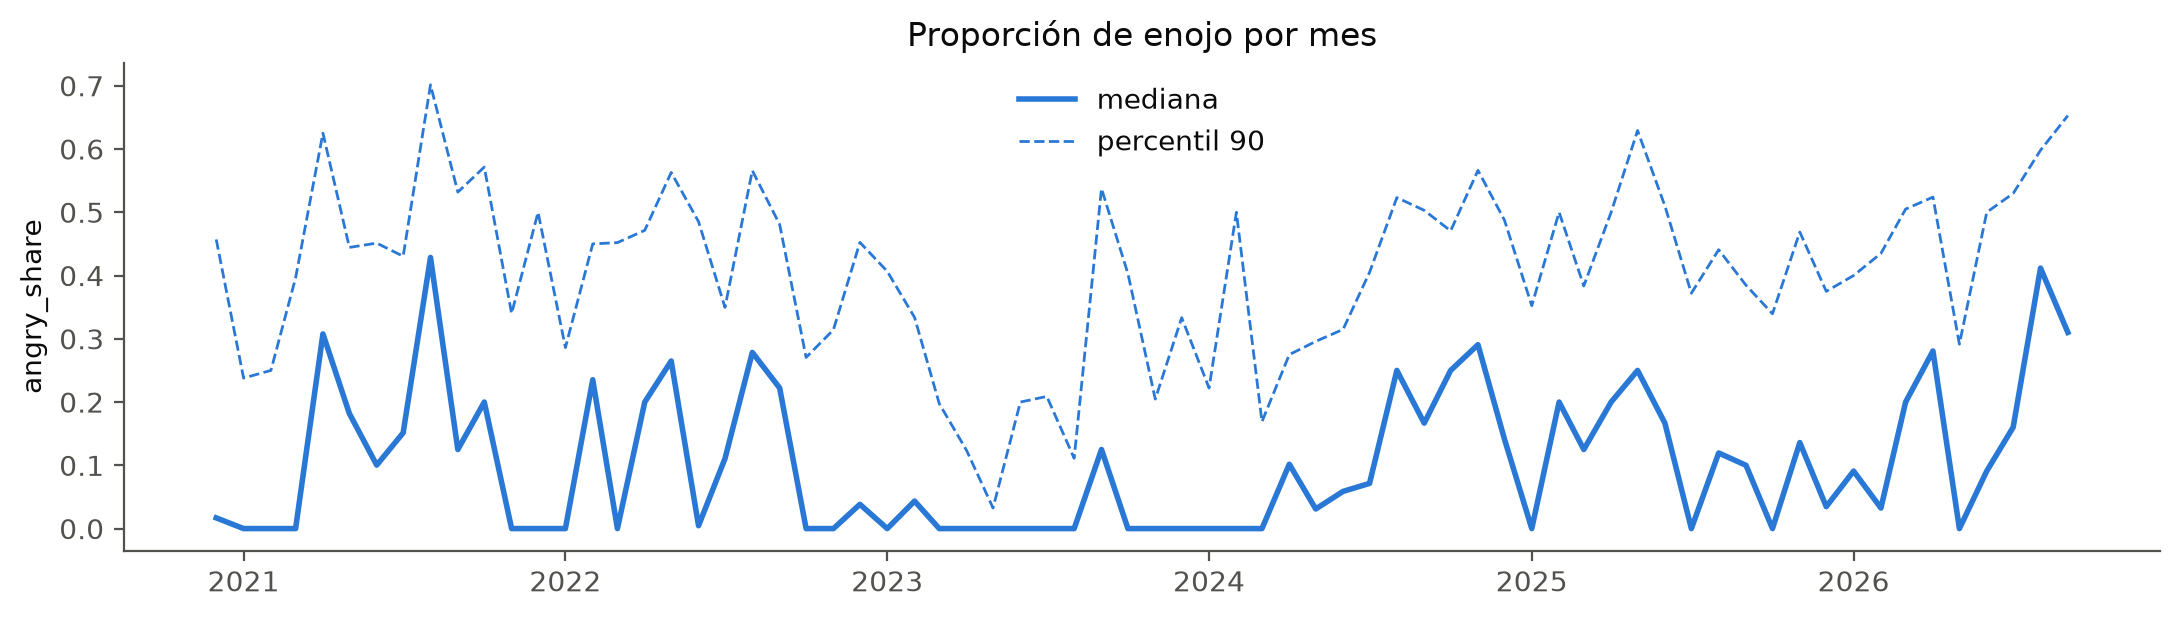

In [ ]:
# Molestia a lo largo del tiempo: mediana mensual de angry_share.
_monthly_anger = posts.groupby(posts["published_at"].dt.to_period("M"))["angry_share"].agg(
    ["median", lambda s: s.quantile(0.9)]
)
_monthly_anger.index = _monthly_anger.index.to_timestamp()
_fig, _ax = plt.subplots(figsize=(11, 3.2))
_ax.plot(
    _monthly_anger.index,
    _monthly_anger["median"],
    color="#2a78d6",
    linewidth=2,
    label="mediana",
)
_ax.plot(
    _monthly_anger.index,
    _monthly_anger.iloc[:, 1],
    color="#2a78d6",
    linewidth=1,
    linestyle="--",
    label="percentil 90",
)
_ax.set_ylabel("angry_share")
_ax.set_title("Proporción de enojo por mes")
_ax.legend(frameon=False)
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

- El volumen sube de ~45 publicaciones al mes en 2021 a 130 a 180 en 2025. Las
  emergencias tienen picos en mayo y junio de 2023 (30 y 33), octubre y noviembre de
  2024 y febrero de 2025 (34).
- `corte_programado` y `restablecimiento` casi no aparecen antes de 2025 (18 a 42 al año)
  y suben a 188 en 2025. Puede ser un cambio real o un cambio en cómo redacta la página
  que las reglas de `event_type` sí reconocen.
- Las medianas de interacción casi no cambian entre tipos de evento (12 reacciones en
  todos menos `pipas`, con 22); `pipas` tiene la mayor proporción de enojo (mediana 0.32
  frente a 0.06 de "otro").
- La página publica en horario de oficina: 84% entre las 7:00 y las 14:59 y solo 9% en
  sábado o domingo.
- La mediana mensual de `angry_share` es 0 en muchos meses de 2022 a 2024; las más altas
  son agosto de 2021 (0.43) y agosto de 2026 (0.41).

## 5. Correlación

Spearman para las numéricas (los conteos no son normales y la relación es monótona más
que lineal; Pearson sobre `log1p` da conclusiones parecidas), V de Cramér con corrección
de sesgo para las categóricas, y razón de correlación (eta) entre `event_type` y las
numéricas.

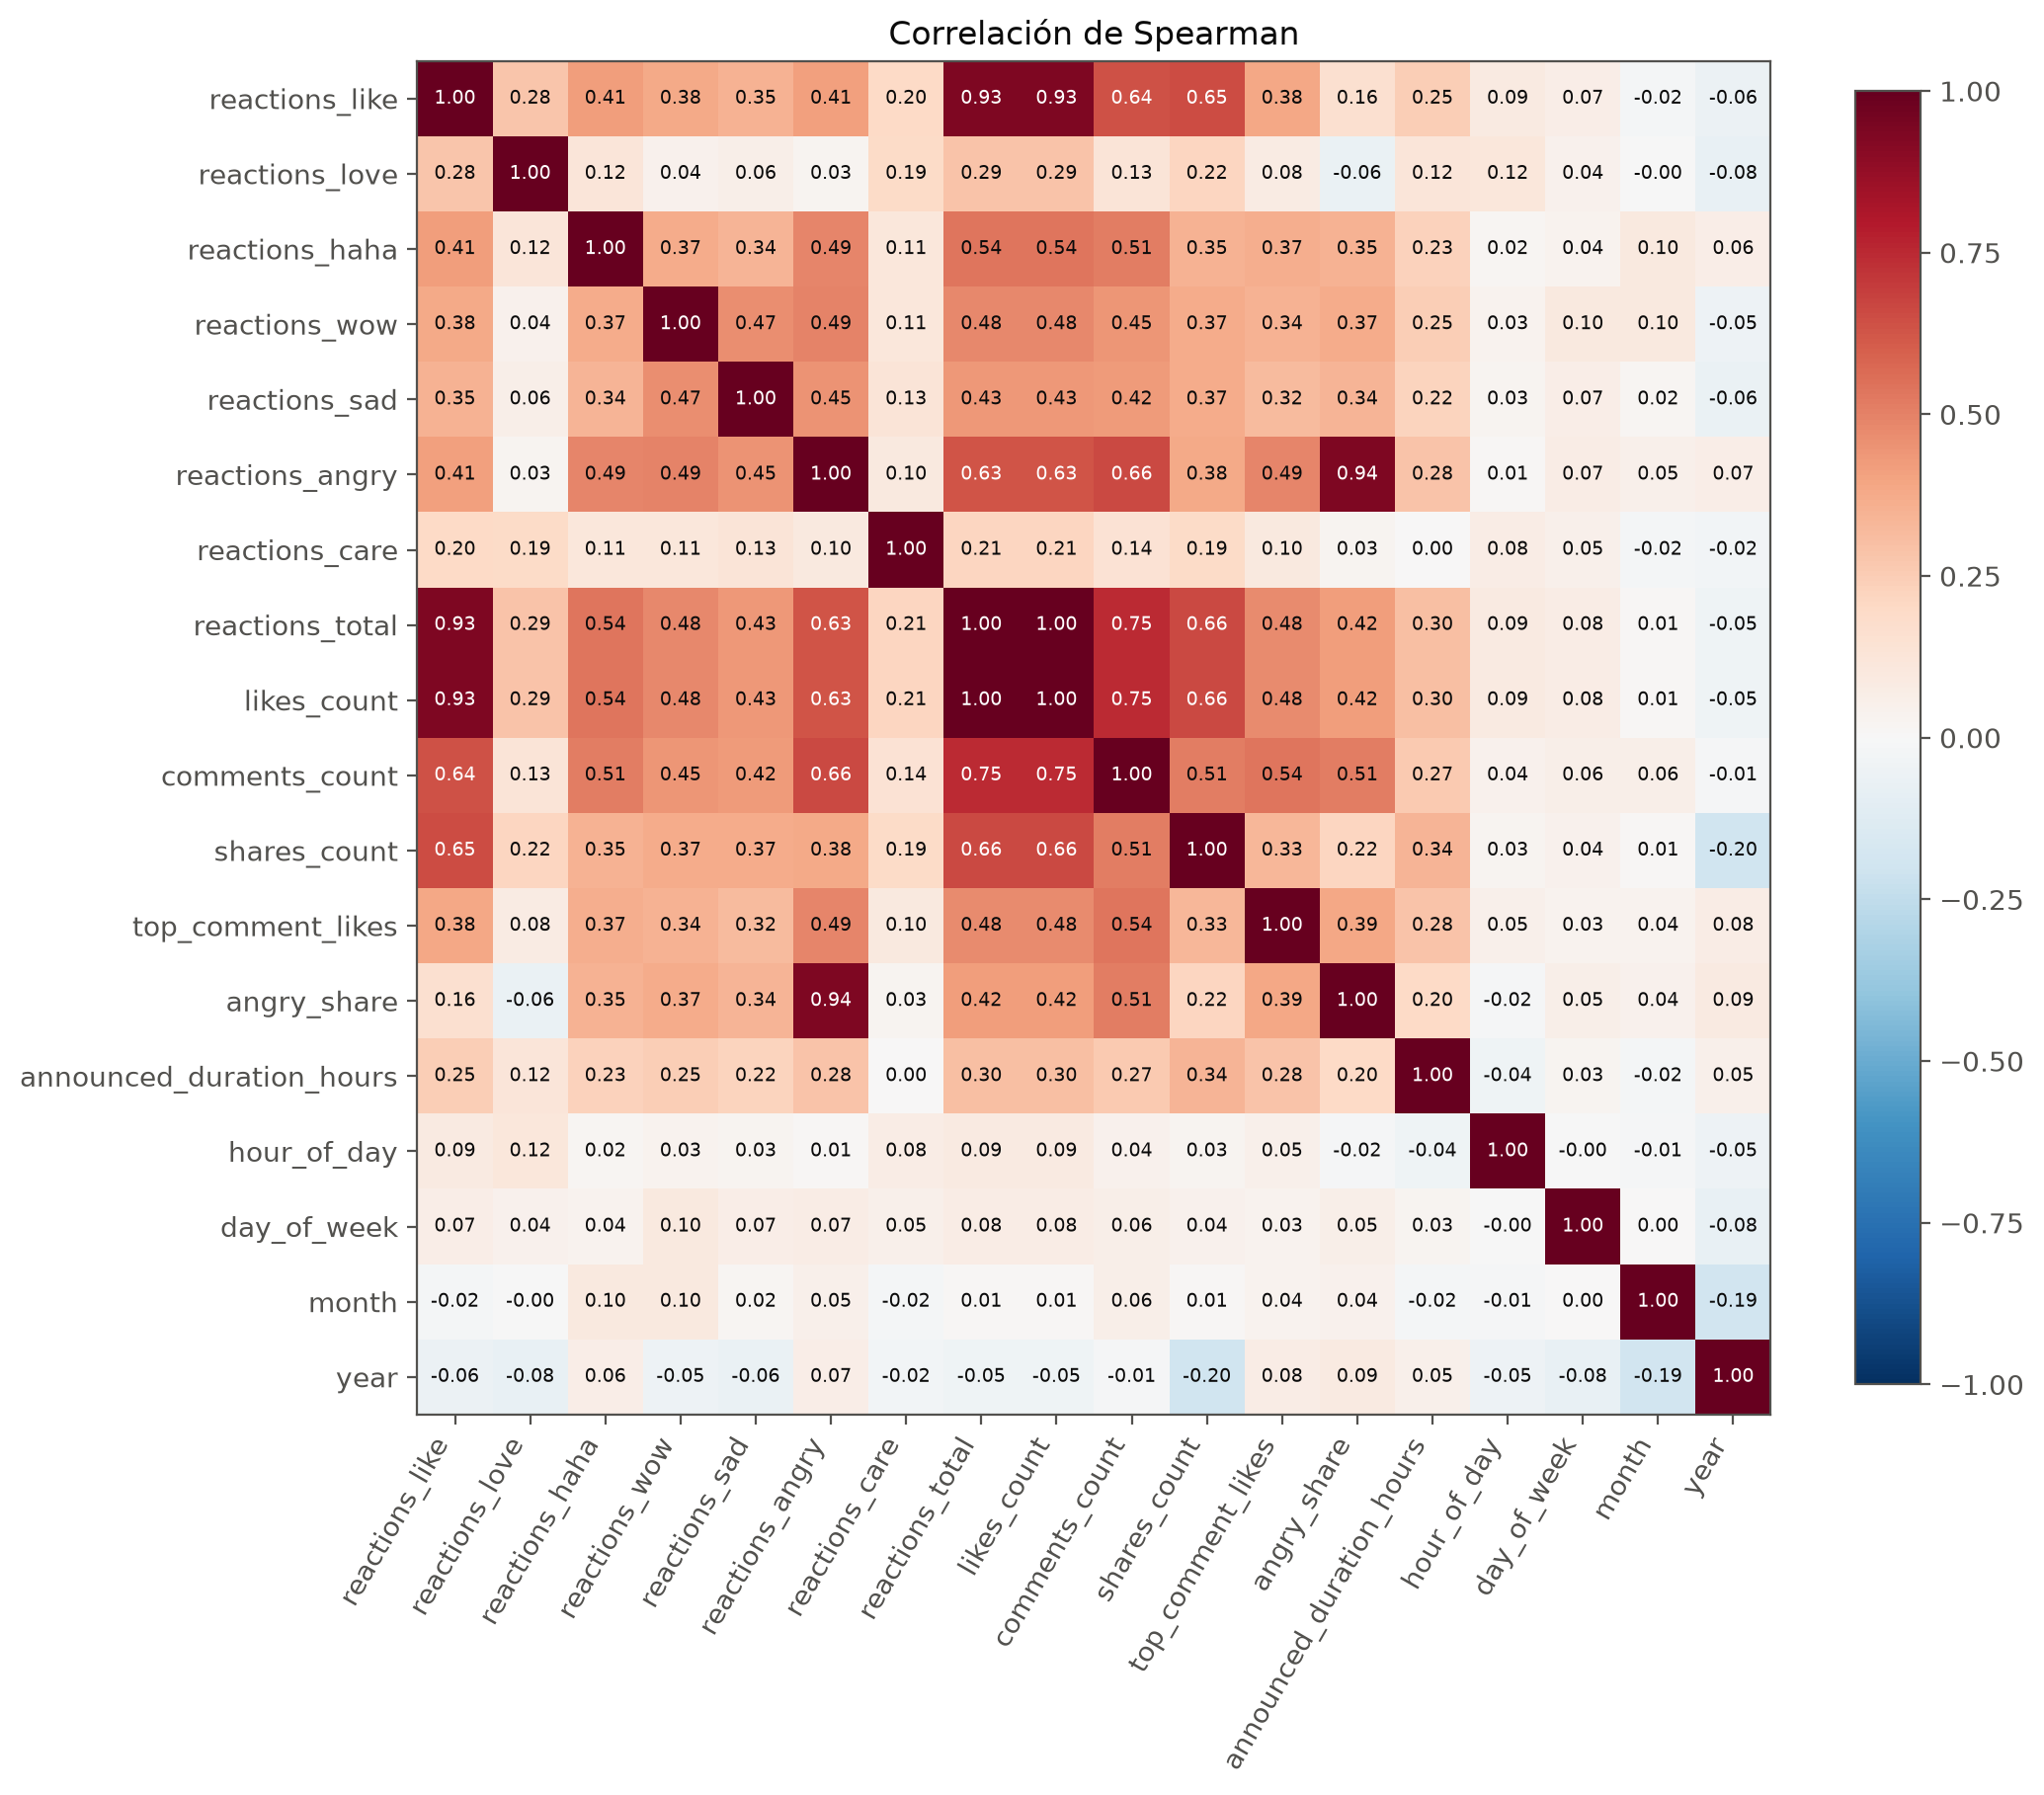

In [ ]:
numeric_columns = [
    "reactions_like",
    "reactions_love",
    "reactions_haha",
    "reactions_wow",
    "reactions_sad",
    "reactions_angry",
    "reactions_care",
    "reactions_total",
    "likes_count",
    "comments_count",
    "shares_count",
    "top_comment_likes",
    "angry_share",
    "announced_duration_hours",
    "hour_of_day",
    "day_of_week",
    "month",
    "year",
]
spearman = posts[numeric_columns].corr("spearman")
plot_heatmap(spearman, "Correlación de Spearman")

In [ ]:
# Pares con |rho| >= 0.6, junto a Pearson sobre log1p para comparar.
_pearson_log = np.log1p(posts[numeric_columns]).corr()
_upper = np.triu(np.ones(spearman.shape, dtype=bool), k=1)
_pairs = spearman.where(_upper).stack().rename("spearman").to_frame()
_pairs["pearson_log1p"] = _pearson_log.where(_upper).stack()
_pairs[_pairs["spearman"].abs() >= 0.6].sort_values("spearman", ascending=False).round(3)

spearman pearson_log1p reactions_total likes_count 1.000 1.000 reactions_angry angry_share 0.935 0.828 reactions_like reactions_total 0.934 0.940 likes_count 0.934 0.940 reactions_total comments_count 0.748 0.775 likes_count comments_count 0.748 0.775 reactions_total shares_count 0.661 0.743 likes_count shares_count 0.661 0.743 reactions_angry comments_count 0.658 0.731 reactions_like shares_count 0.651 0.729 comments_count 0.636 0.659 reactions_angry reactions_total 0.629 0.705 likes_count 0.629 0.705

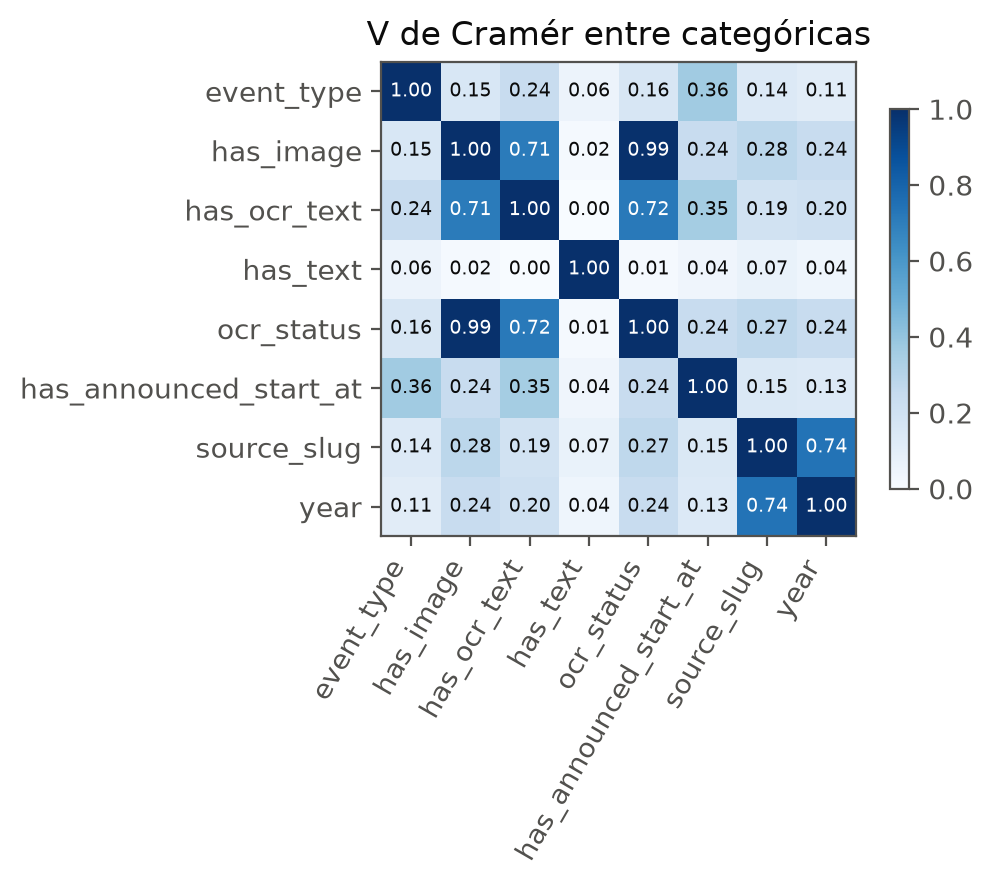

In [ ]:
categorical_columns = [
    "event_type",
    "has_image",
    "has_ocr_text",
    "has_text",
    "ocr_status",
    "has_announced_start_at",
    "source_slug",
    "year",
]
_cramers = cramers_v_matrix(
    posts.astype({column: str for column in categorical_columns}), categorical_columns
)
plot_heatmap(_cramers, "V de Cramér entre categóricas", diverging=False)

In [ ]:
pd.Series(
    {
        column: correlation_ratio(
            posts["event_type"],
            posts[column] if column == "angry_share" else np.log1p(posts[column]),
        )
        for column in [
            "reactions_total",
            "reactions_angry",
            "angry_share",
            "comments_count",
            "shares_count",
            "hour_of_day",
        ]
    },
    name="eta con event_type",
).round(3).to_frame()

,eta con event_type
reactions_total,0.064
reactions_angry,0.122
angry_share,0.090
comments_count,0.092
shares_count,0.097
hour_of_day,0.079


Redundancias (correlación 1 o casi 1 por construcción, no relaciones):

- `likes_count` = `reactions_total` (rho = 1) y `reactions_like` domina el total (0.93).
- `angry_share` y `reactions_angry` (0.94): una es la otra dividida entre el total.
- `ocr_status` y `has_image` (V = 0.99); `month` e `iso_week`; `source_slug` y `year` (0.74).

Relaciones:

- El enojo acompaña a la conversación: `reactions_angry` con `comments_count` (0.66) más
  que con `shares_count` (0.38). Las publicaciones que enojan se comentan, no se
  comparten.
- `announced_duration_hours` correlaciona poco con la interacción (0.2 a 0.3): un corte
  anunciado más largo no genera mucha más reacción.
- `event_type` explica menos del 2% de la varianza de cualquier métrica de interacción
  (eta <= 0.12). La clasificación por reglas no separa publicaciones por su recepción.
- `has_announced_start_at` es la categórica más asociada con `event_type` (V = 0.36),
  por los cortes programados.

## 6. Reducción de dimensión para visualización

Se comparan PCA (lineal, conserva varianza global), t-SNE (no lineal, conserva vecindades
locales) y UMAP (no lineal, vecindades locales y algo más de estructura global) sobre dos
espacios de variables:

1. Interacción y metadatos: 10 conteos en `log1p`, `angry_share`, la hora como seno y
   coseno, `has_image`, `has_ocr_text`, `has_announced_start_at` y la longitud del texto.
   17 variables estandarizadas.
2. Texto: TF-IDF de `text` + `ocr_text` (unigramas y bigramas que aparecen en al menos 5
   publicaciones) reducido a 50 componentes con SVD truncado.

La calidad de cada proyección se mide con trustworthiness (1 = los 10 vecinos más cercanos
en 2D también lo son en el espacio original).

In [ ]:
_counts = [
    column
    for column in posts
    if column.startswith("reactions_") and column != "reactions_total"
] + ["comments_count", "shares_count", "top_comment_likes"]
engagement_features = np.log1p(posts[_counts]).assign(
    angry_share=posts["angry_share"].fillna(0),
    hour_sin=np.sin(2 * np.pi * posts["hour_of_day"] / 24),
    hour_cos=np.cos(2 * np.pi * posts["hour_of_day"] / 24),
    has_image=posts["has_image"].astype(int),
    has_ocr_text=posts["has_ocr_text"].astype(int),
    has_announced=posts["has_announced_start_at"].astype(int),
    text_length=np.log1p(posts["text"].str.len()),
)
engagement_matrix = StandardScaler().fit_transform(engagement_features)
engagement_matrix.shape

In [ ]:
_pca = PCA().fit(engagement_matrix)
pca_summary = pd.DataFrame(
    {
        "varianza explicada": _pca.explained_variance_ratio_[:6],
        "acumulada": _pca.explained_variance_ratio_[:6].cumsum(),
    },
    index=[f"PC{i}" for i in range(1, 7)],
).round(3)
pca_loadings = pd.DataFrame(
    _pca.components_[:2].T, index=engagement_features.columns, columns=["PC1", "PC2"]
).round(2)
pca_summary

,varianza explicada,acumulada
PC1,0.312,0.312
PC2,0.126,0.438
PC3,0.094,0.533
PC4,0.066,0.598
PC5,0.058,0.656
PC6,0.052,0.709


In [ ]:
pca_loadings.sort_values("PC1", ascending=False)

,PC1,PC2
reactions_angry,0.37,0.09
comments_count,0.37,0.00
shares_count,0.33,-0.07
reactions_like,0.32,-0.21
reactions_wow,0.31,-0.04
top_comment_likes,0.31,-0.01
reactions_sad,0.30,-0.02
reactions_haha,0.30,-0.02
angry_share,0.23,0.22
reactions_care,0.13,-0.23


In [ ]:
engagement_embeddings = embed_2d(engagement_matrix)

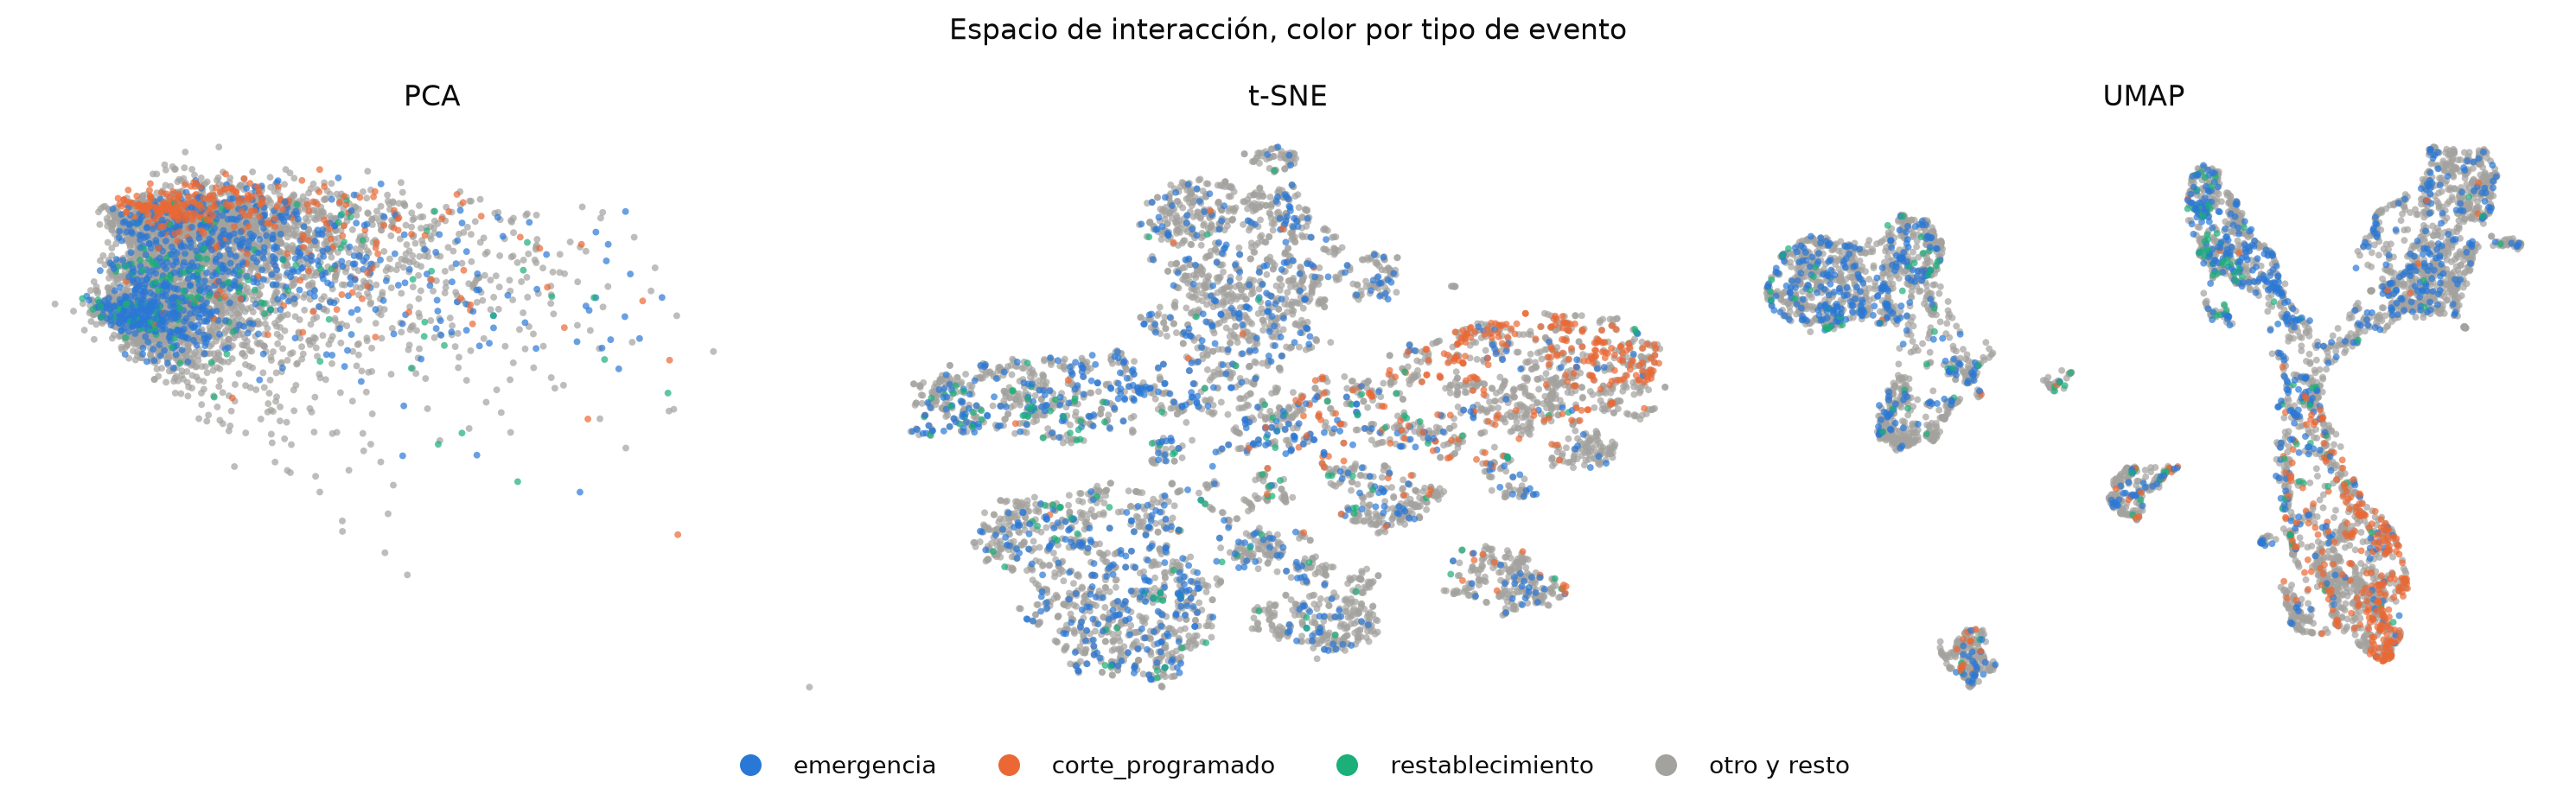

In [ ]:
plot_embeddings(
    engagement_embeddings,
    posts["event_type"],
    "Espacio de interacción, color por tipo de evento",
)

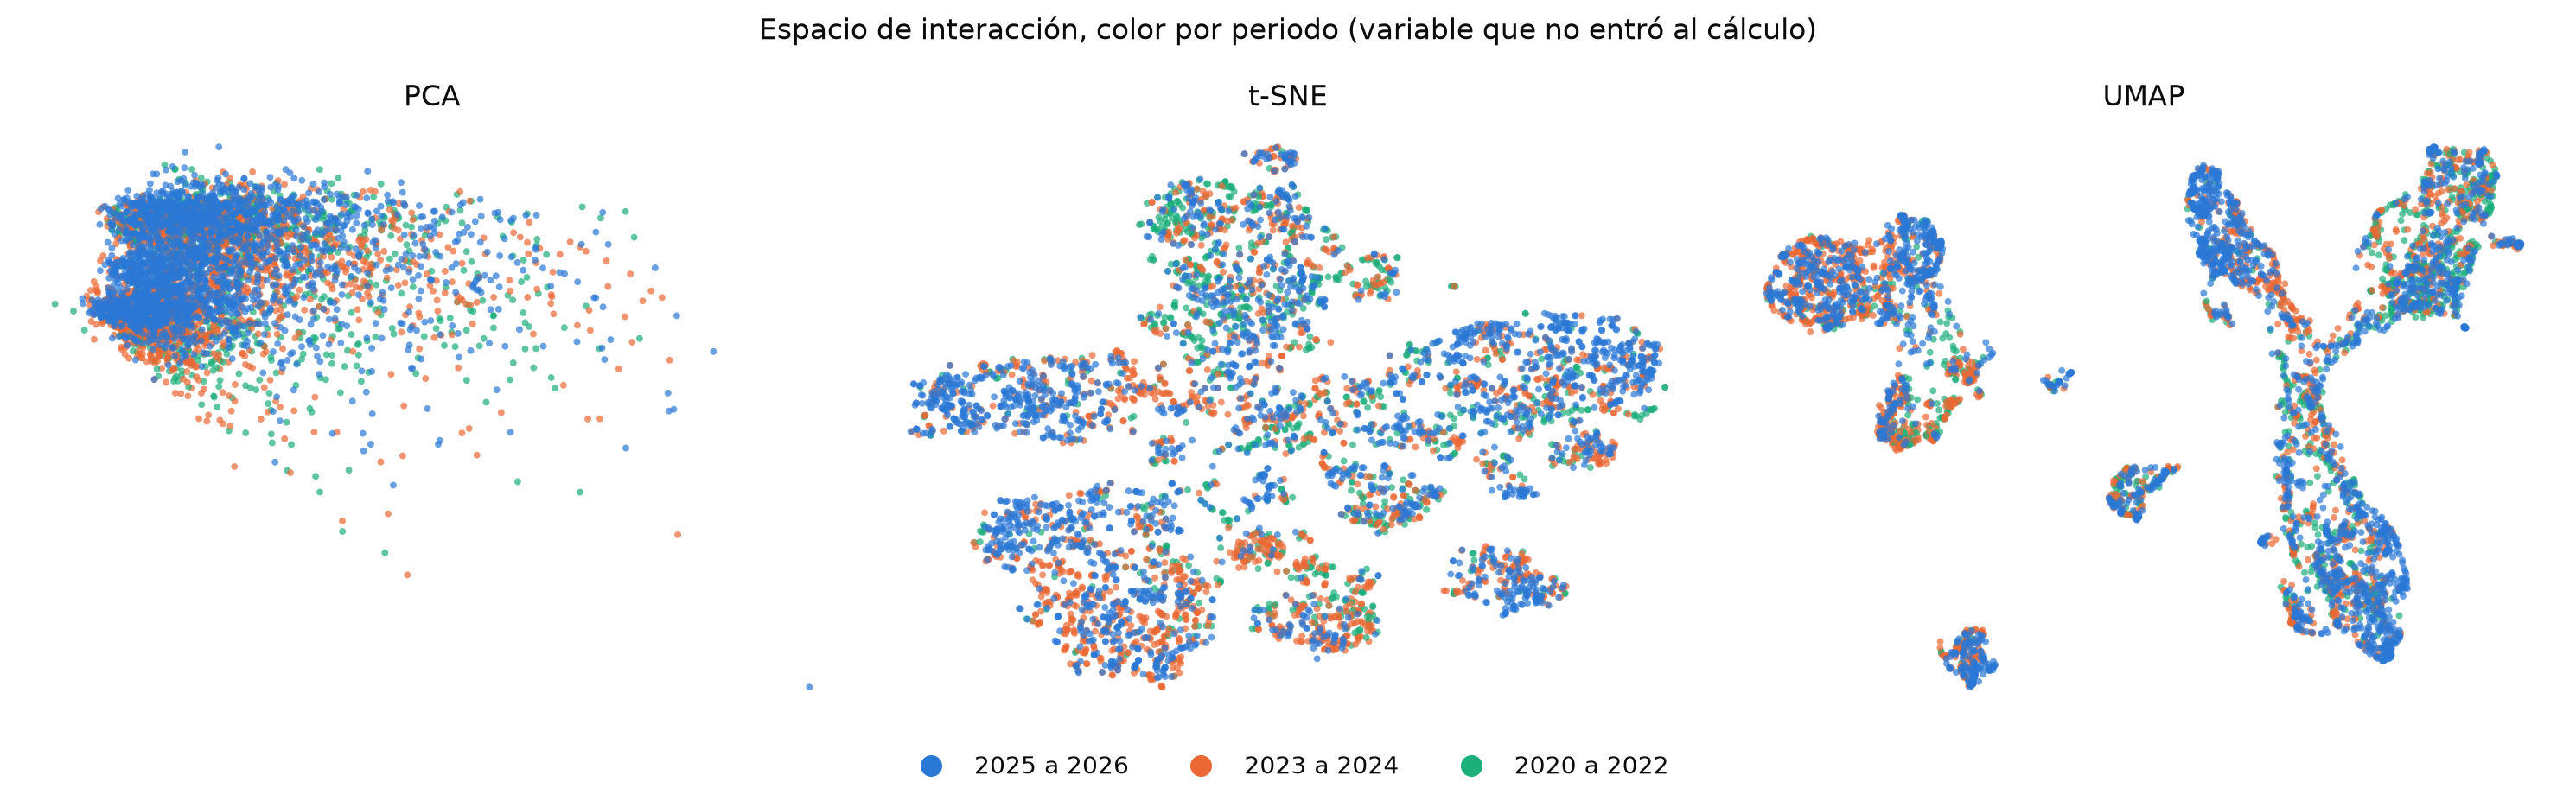

In [ ]:
# El año no entra al espacio de interacción, así que colorear por él sí prueba algo.
_period = pd.cut(
    posts["year"],
    bins=[2019, 2022, 2024, 2026],
    labels=["2020 a 2022", "2023 a 2024", "2025 a 2026"],
).astype(str)
plot_embeddings(
    engagement_embeddings,
    _period,
    "Espacio de interacción, color por periodo (variable que no entró al cálculo)",
)

In [ ]:
_documents = (posts["text"] + " " + posts["ocr_text"]).str.lower()
_tfidf = TfidfVectorizer(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
_terms = _tfidf.fit_transform(_documents)
text_matrix = StandardScaler().fit_transform(
    TruncatedSVD(n_components=50, random_state=42).fit_transform(_terms)
)
text_matrix.shape

In [ ]:
text_embeddings = embed_2d(text_matrix)

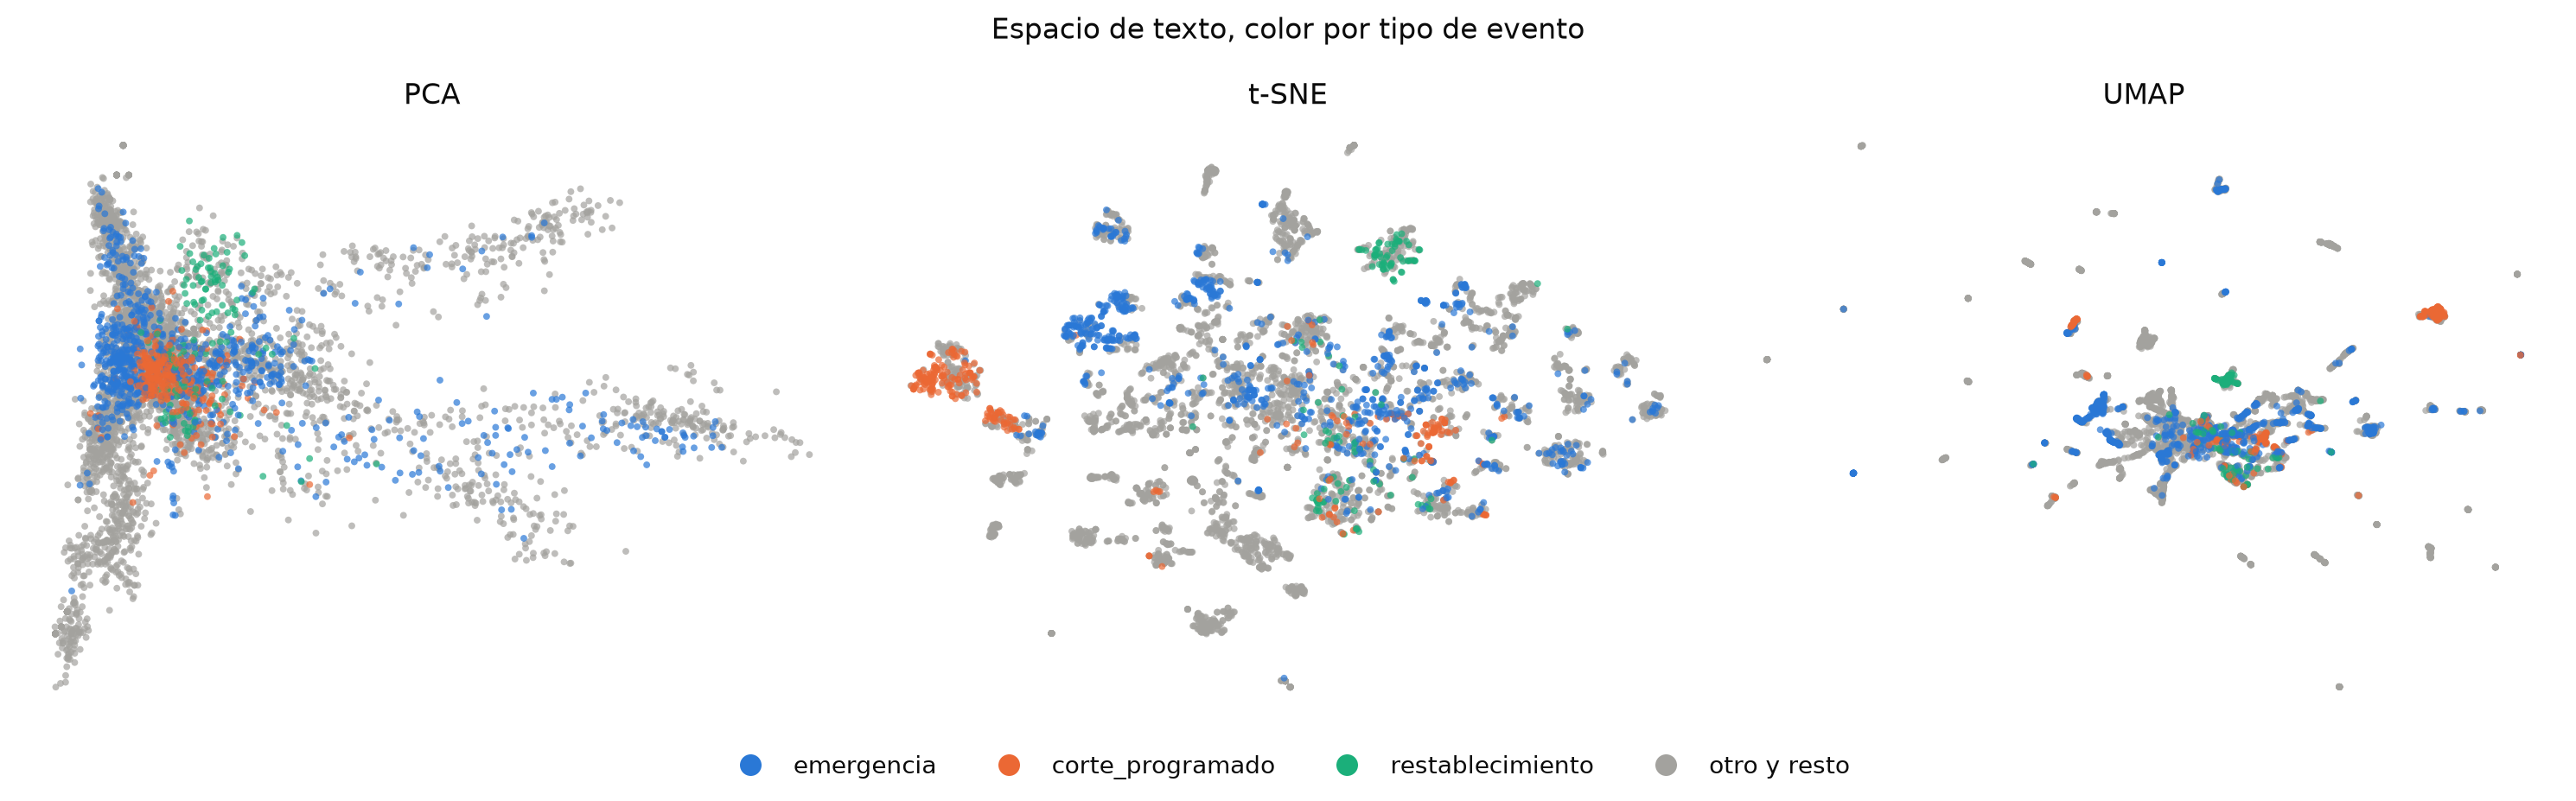

In [ ]:
plot_embeddings(
    text_embeddings, posts["event_type"], "Espacio de texto, color por tipo de evento"
)

In [ ]:
pd.DataFrame(
    {
        "interacción": embedding_quality(engagement_matrix, engagement_embeddings),
        "texto": embedding_quality(text_matrix, text_embeddings),
    }
)

,interacción,texto
PCA,0.816,0.721
t-SNE,0.989,0.992
UMAP,0.970,0.983


- PCA: las dos primeras componentes explican 44% de la varianza. PC1 es el volumen de
  interacción (todas las cargas positivas, enojo y comentarios las mayores); PC2 la
  dominan `has_image` y `has_ocr_text` (0.53 cada una). En 2D es una nube sin grupos y la
  peor trustworthiness (0.82 en interacción, 0.72 en texto).
- t-SNE y UMAP conservan las vecindades (0.97 a 0.99). En el espacio de interacción los
  grupos que se ven los definen sobre todo las variables binarias de entrada (imagen, OCR,
  fecha anunciada); no se grafican coloreados por ellas porque sería circular. Lo que sí
  es una prueba: coloreando por `event_type` y por periodo (ninguno entra al cálculo) los
  colores se mezclan dentro de cada grupo. Ni el tipo de evento ni la época separan la
  forma de interacción, coherente con eta.
- En el espacio de texto `corte_programado` y `restablecimiento` forman islas compactas
  en t-SNE y UMAP: el texto los distingue. `emergencia` se reparte en varias islas, y
  "otro" (75% del total) se divide en muchas islas grises bien separadas, es decir, temas
  recurrentes que hoy no tienen etiqueta.
- Para visualizar este dataset conviene t-SNE (mejor separación local, más lento) o UMAP
  (casi igual de fiel y más rápido); PCA sirve para interpretar ejes, no para ver grupos.

## 7. Consulta con los usuarios

El tablero final está pensado para quien da seguimiento al desabasto de agua en
Hermosillo (ciudadanía, periodistas o el propio organismo; el público aún está por
definir en el README). Estas son las preguntas que deja la exploración, para llevarlas a
esa consulta. Las respuestas se registrarán aquí y en `docs/eda.md`.

| # | Hallazgo | Pregunta |
|---|---|---|
| 1 | "otro" es 75% de las publicaciones y en el espacio de texto forma muchos grupos separados | ¿Qué temas además de cortes, emergencias, restablecimientos y pipas les interesa distinguir (turbiedad, pagos, campañas, obras)? |
| 2 | Las publicaciones con más interacción vienen en rachas sobre un mismo problema (rupturas de febrero de 2024, turbiedad de julio de 2026) | ¿Les sirve más ver publicaciones sueltas o episodios que agrupen varios días de avisos sobre el mismo problema? |
| 3 | Solo 30% de los avisos declara fecha de inicio y 11% una duración | ¿La duración anunciada es un dato que buscan? Si lo es, vale la pena extraerla también del OCR con más reglas. |
| 4 | El enojo acompaña a los comentarios, no a los compartidos | ¿`angry_share` es la medida de molestia que reconocen, o prefieren el número de comentarios o el texto de los comentarios? |
| 5 | Faltan publicaciones del 5 al 19 de abril de 2024 y agosto a septiembre de 2026 parece incompleto | ¿Recuerdan eventos en esas fechas que deban recuperarse antes de publicar series mensuales? |